# Clustering-based drift explanations: experiments

This notebook compares three data-drift detectors of STRIDE on the same pair of data blocks
(a reference block before the drift and a detection block after it) and shows the explanations
each of them gives:

1. **Descriptive statistics** (`DescriptiveStatisticsDriftDetector`) – relative change of the class-wise mean, median and standard deviation of every feature.
2. **Statistical tests** (`StatisticalTestsDriftDetector`) – Kolmogorov–Smirnov and Anderson–Darling tests, Jensen–Shannon divergence and Wasserstein distance per feature and class.
3. **Clustering dynamics** (`ClusterBasedDriftDetector`) – X-Means clusters of every class in the reference block, assignment of the detection block to these clusters, appeared and disappeared clusters, centroid shifts, changes of per-cluster statistics and spread, and a permutation test for the decision.

The method of the cluster detector is described in `docs/user-guide/clustering-dynamics.md`.

**Running.** Use the project environment (`bachelor_venv`) as the kernel. The notebook works from the repository root or from `notebooks/`; if `stride` is not installed, `src/` is added to the path. Figures are saved to `notebooks/output/clustering_experiments/` when `SAVE_FIGURES = True`. A full run takes a few minutes, most of it the permutation test of the cluster detector.

## 0. Setup

In [1]:
import sys
import warnings
from enum import Enum
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
try:
    import stride  # noqa: F401
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))

from stride.datasets import get_dataset
from stride.xai.clustering import (
    ClusterBasedDriftDetector,
    plot_centers_shift,
    plot_clusters_by_class,
    plot_drift_clustered,
)
from stride.xai.stats import (
    DescriptiveStatisticsDriftDetector,
    StatisticalTestsDriftDetector,
    StatisticalTestType,
    PlotOptions,
    StatisticsType,
    plot_boxplot,
    plot_histogram,
)

warnings.filterwarnings("ignore", category=FutureWarning)
# scipy's Anderson-Darling test clips its p-value to [0.001, 0.25] and warns about it.
warnings.filterwarnings("ignore", message="p-value (capped|floored)")
warnings.filterwarnings("ignore", message="Parameter `variant` has been introduced")
pd.set_option("display.precision", 3)
pd.set_option("display.max_rows", 200)

SIZE_OF_BLOCK = 1000
RANDOM_STATE = 42
N_FEATURE_PLOTS = 3  # features with the strongest KS evidence are plotted per dataset
SAVE_FIGURES = False
OUTPUT_DIR = ROOT / "notebooks" / "output" / "clustering_experiments"

In [2]:
class DatasetType(Enum):
    Hyperplane = "hyperplane_drift"
    SEA = "sea_drift"
    LWI = "linear_weight_inversion_drift"
    RBF = "rbf_drift"
    RandomTreeMulti = "random_tree_multi_window"


RESULTS = {}

### Helper functions

In [3]:
def load_blocks(dataset_type, size_of_block=SIZE_OF_BLOCK, boxes=(0, 1), **kwargs):
    """Generate a stream and cut out two blocks of `size_of_block` samples.

    `boxes` are block indices in the stream; the default `(0, 1)` compares the block before the
    drift with the block after it for the two-block datasets.
    """
    generator = get_dataset(dataset_type.value)
    if "num_windows" not in kwargs:
        kwargs = {"n_samples_before": size_of_block, "n_samples_after": size_of_block, **kwargs}
    X, y = generator.generate(**kwargs)
    y = pd.Series(np.asarray(y), name="label")

    def block(i):
        rows = slice(i * size_of_block, (i + 1) * size_of_block)
        return X.iloc[rows].reset_index(drop=True), y.iloc[rows].reset_index(drop=True)

    return (*block(boxes[0]), *block(boxes[1]))


def run_detectors(X_old, y_old, X_new, y_new):
    dsdd = DescriptiveStatisticsDriftDetector(X_old, y_old, X_new, y_new)
    dsdd.detect([StatisticsType.Mean, StatisticsType.Median, StatisticsType.StandardDeviation])

    stdd = StatisticalTestsDriftDetector(X_old, y_old, X_new, y_new)
    stdd.detect(
        [
            StatisticalTestType.KolmogorovSmirnov,
            StatisticalTestType.AD,
            StatisticalTestType.JensenShannon,
            StatisticalTestType.WassersteinDistance,
        ]
    )

    cbdd = ClusterBasedDriftDetector(X_old, y_old, X_new, y_new, random_state=RANDOM_STATE)
    cbdd.detect()
    return dsdd, stdd, cbdd


def show(fig, name=None, dataset_type=None):
    """Display a figure in place (not at the end of the cell) and optionally save it."""
    if SAVE_FIGURES and name is not None:
        out = OUTPUT_DIR / dataset_type.name
        out.mkdir(parents=True, exist_ok=True)
        fig.savefig(out / f"{name}.png", bbox_inches="tight")
    display(fig)
    plt.close(fig)


def header(text):
    display(Markdown(text))

In [4]:
def descriptive_table(dsdd):
    """Class-wise statistics before and after the drift with their relative change."""
    stats = dsdd.calculate_stats_before_after()
    rows = []
    for cl, features in dsdd.stat_shifts.items():
        for feature, shifts in features.items():
            for stat, change in shifts.items():
                rows.append(
                    {
                        "class": cl,
                        "feature": feature,
                        "statistic": stat,
                        "before": stats[("old", feature, stat)][cl],
                        "after": stats[("new", feature, stat)][cl],
                        "relative change": change,
                    }
                )
    table = pd.DataFrame(rows).pivot(index=["class", "feature"], columns="statistic").swaplevel(axis=1)
    columns = pd.MultiIndex.from_product([["mean", "median", "std"], ["before", "after", "relative change"]])
    order = pd.MultiIndex.from_product([sorted(dsdd.stat_shifts), dsdd.data_before.columns.drop("label")])
    return table.reindex(index=order, columns=columns).rename_axis(["class", "feature"])


def statistical_tests_table(stdd):
    """p-values and divergences per class and feature; '*' marks values that signal drift."""
    columns = {
        "kolmogorov_smirnov": ("KS p-value", "p_value"),
        "anderson_darling": ("AD p-value", "p_value"),
        "jensen_shannon": (f"JS divergence (thr {stdd.js_thr})", "js_div"),
        "wasserstein": (f"Wasserstein (thr {stdd.wasserstein_thr})", "wd"),
    }
    rows = {}
    for test, (name, key) in columns.items():
        for cl, features in stdd.drift_details[test].items():
            for feature, detail in features.items():
                value = f"{detail[key]:.3f}" + (" *" if detail["drift"] else "")
                rows.setdefault((cl, feature), {})[name] = value
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.names = ["class", "feature"]
    return table


def strongest_ks_features(stdd, n):
    p_values = {}
    for features in stdd.drift_details["kolmogorov_smirnov"].values():
        for feature, detail in features.items():
            p_values[feature] = min(p_values.get(feature, 1.0), detail["p_value"])
    return sorted(p_values, key=p_values.get)[:n]

In [5]:
def cluster_table(cbdd):
    """One row per cluster: class, size in both blocks, status, centroid shift and spread."""
    y_old, y_new = np.asarray(cbdd.y_old), np.asarray(cbdd.y_new)
    rows = []
    for k in sorted(set(cbdd.cluster_labels_old) | set(cbdd.cluster_labels_new)):
        in_old, in_new = cbdd.cluster_labels_old == k, cbdd.cluster_labels_new == k
        shift = cbdd.cluster_shifts[k]
        tracked = isinstance(shift, dict)
        rows.append(
            {
                "cluster": int(k),
                "class": (y_old[in_old] if in_old.any() else y_new[in_new])[0],
                "n before": int(in_old.sum()),
                "n after": int(in_new.sum()),
                "status": "tracked" if tracked else shift,
                "centroid shift": shift["euclidean_distance"] if tracked else np.nan,
                "spread before": cbdd.avg_distance_old.get(k, np.nan),
                "spread after": cbdd.avg_distance_new.get(k, np.nan),
                "spread change": cbdd.avg_distance_shift.get(k, np.nan) if tracked else np.nan,
            }
        )
    return pd.DataFrame(rows).set_index("cluster")


def criteria_table(cbdd):
    """Triggered / evaluated checks of every criterion and class."""

    def ratio(flags):
        flags = list(flags)
        return f"{sum(flags)}/{len(flags)}"

    rows = {}
    for cl, d in cbdd.drift_details.items():
        stats = [v for per_feature in d["desc_stats_changes"].values() for s in per_feature.values() for v in s.values()]
        rows[cl] = {
            "clusters appeared/disappeared": bool(d["nr_of_clusters"]),
            "centroid shift": ratio(d["centroid_shift"].values()),
            "descriptive statistics": ratio(stats),
            "spread": ratio(d["avg_distance_to_center"].values()),
        }
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "class"
    return table


def stats_shift_table(cbdd):
    """Change of per-cluster statistics of tracked clusters, in standard deviations of the feature."""
    tracked = [k for k, v in cbdd.cluster_shifts.items() if isinstance(v, dict)]
    if not tracked:
        return None
    table = pd.DataFrame.from_dict(
        {(int(k), f): s for k in tracked for f, s in cbdd.stats_shifts[k].items()}, orient="index"
    )
    order = pd.MultiIndex.from_product([sorted(int(k) for k in tracked), cbdd.columns], names=["cluster", "feature"])
    return table.reindex(order)[["mean", "median", "std"]]


def highlight_threshold(thr):
    return lambda v: "font-weight: bold; color: #c0392b" if pd.notna(v) and abs(v) > thr else ""


def plot_null_distribution(cbdd):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.hist(cbdd.null_strengths, bins=15, color="#95a5a6", edgecolor="white", label="permuted blocks (no drift)")
    ax.axvline(cbdd.strength_of_drift, color="#c0392b", lw=2, label=f"observed, p = {cbdd.p_value:.3f}")
    ax.set_xlabel("drift strength")
    ax.set_ylabel("count")
    ax.set_title("Permutation test of the drift strength")
    ax.legend()
    fig.tight_layout()
    return fig

In [6]:
def run_experiment(dataset_type, **kwargs):
    X_old, y_old, X_new, y_new = load_blocks(dataset_type, **kwargs)
    dsdd, stdd, cbdd = run_detectors(X_old, y_old, X_new, y_new)
    RESULTS[dataset_type.name] = (dsdd, stdd, cbdd)
    save = {"dataset_type": dataset_type}

    header(
        f"**{X_old.shape[1]} features, {len(X_old)} + {len(X_new)} samples.** "
        f"Class counts before: {y_old.value_counts().sort_index().to_dict()}, "
        f"after: {y_new.value_counts().sort_index().to_dict()}"
    )

    # 1. Descriptive statistics
    header(f"#### Descriptive statistics — drift detected: **{dsdd.drift_flag}**")
    display(
        descriptive_table(dsdd).style.format("{:.3f}").format("{:+.1%}", subset=pd.IndexSlice[:, (slice(None), "relative change")])
    )
    features = strongest_ks_features(stdd, N_FEATURE_PLOTS)
    show(plot_boxplot(X_old[features], y_old, X_new[features], y_new, show_=PlotOptions.Both), "boxplot", **save)
    show(plot_histogram(X_old[features], y_old, X_new[features], y_new), "histogram", **save)

    # 2. Statistical tests
    header(f"#### Statistical tests — drift detected: **{stdd.drift_flag}**")
    display(pd.Series(stdd.drift_flags, name="drift detected").to_frame().T)
    display(statistical_tests_table(stdd))

    # 3. Clustering dynamics
    null_95 = np.percentile(cbdd.null_strengths, 95)
    header(
        f"#### Clustering dynamics — drift detected: **{cbdd.drift_flag}**\n\n"
        f"Drift strength **{cbdd.strength_of_drift:.3f}**, permutation p-value **{cbdd.p_value:.3f}** "
        f"(95th percentile of the strength without drift: {null_95:.3f}). "
        f"Clusters: {cbdd.number_of_clusters_old} in the reference block, "
        f"{cbdd.number_of_clusters_new} in the detection block."
    )
    show(plot_null_distribution(cbdd), "permutation_test", **save)

    header("Triggered / evaluated checks per class and criterion:")
    display(criteria_table(cbdd))

    header(
        "Clusters (distances in standardised feature space; centroid shift threshold "
        f"{cbdd.thr_centroid_shift:.2f}, spread change threshold {cbdd.thr_avg_distance_to_center_change:.0%}):"
    )
    display(cluster_table(cbdd).style.format(precision=3).format("{:+.1%}", subset=["spread change"], na_rep="–"))

    stats_shifts = stats_shift_table(cbdd)
    if stats_shifts is None:
        header("No cluster is present in both blocks, so per-cluster statistics are not compared.")
    else:
        header(f"Change of per-cluster statistics in standard deviations (bold: above `thr_desc_stats` = {cbdd.thr_desc_stats}):")
        display(stats_shifts.style.format("{:+.3f}").map(highlight_threshold(cbdd.thr_desc_stats)))

    labels_old, labels_new = cbdd.cluster_labels_old, cbdd.cluster_labels_new
    show(plot_drift_clustered(X_old, X_new, y_old, y_new, labels_old, labels_new), "clusters", **save)
    show(plot_clusters_by_class(X_old, X_new, y_old, y_new, labels_old, labels_new), "clusters_by_class", **save)
    show(plot_centers_shift(X_old, X_new, y_old, y_new, labels_old, labels_new), "centers_shift", **save)

## 1. SEA

**3 features, 1000 + 1000 samples.** Class counts before: {False: 301, True: 699}, after: {False: 431, True: 569}

#### Descriptive statistics — drift detected: **True**

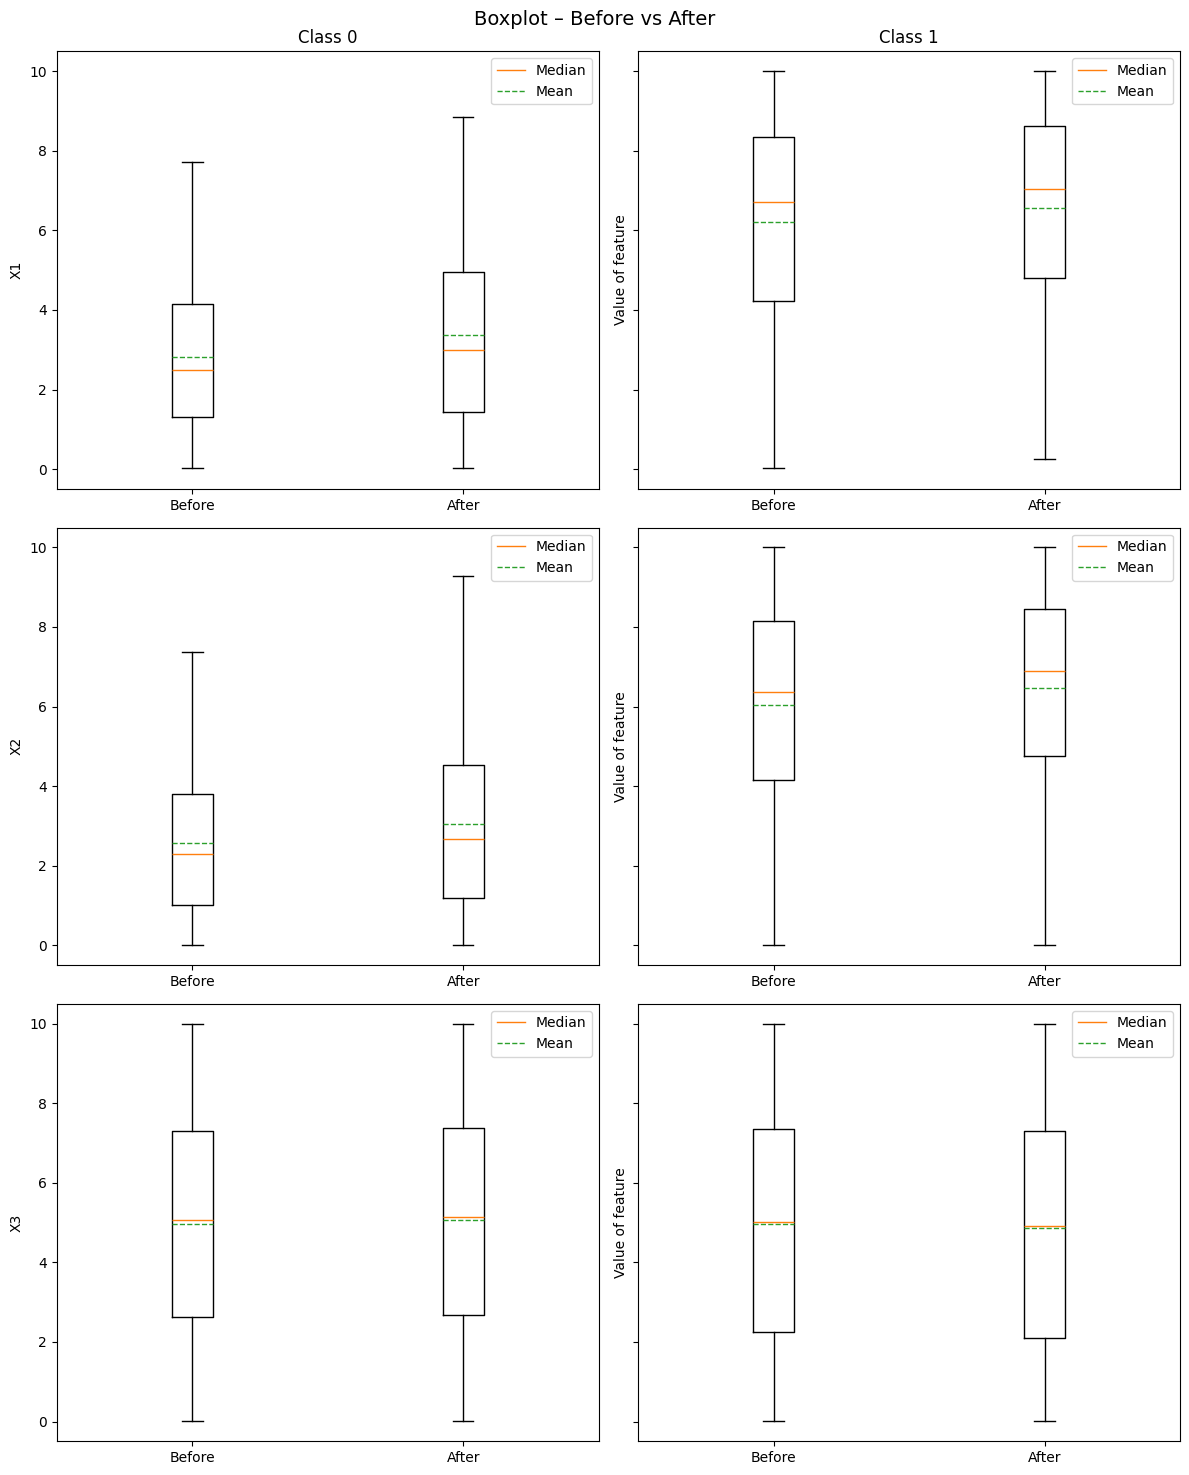

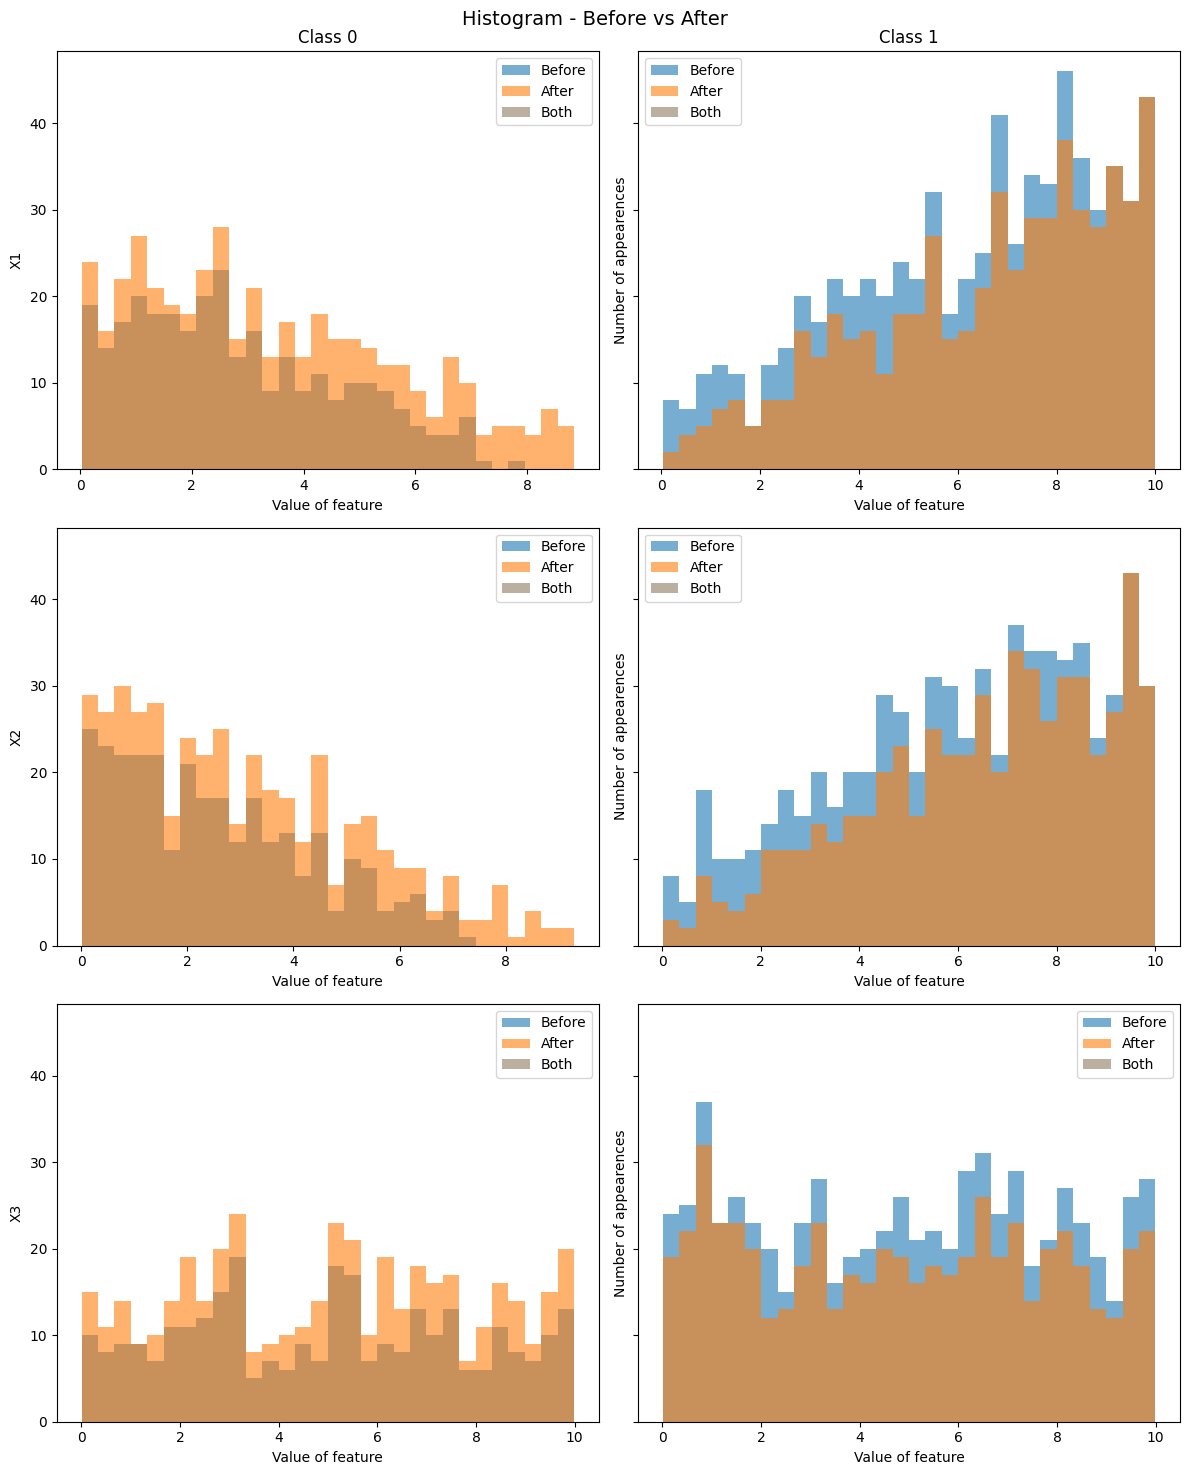

#### Statistical tests — drift detected: **False**

,kolmogorov_smirnov,anderson_darling,jensen_shannon,wasserstein
drift detected,False,True,False,False


KS p-value AD p-value JS divergence (thr 0.05)  \
class feature                                                  
False X1         0.029 *    0.001 *                    0.009   
      X2           0.100    0.008 *                    0.006   
      X3           0.996      0.250                    0.003   
True  X1           0.262    0.034 *                    0.004   
      X2           0.081    0.007 *                    0.005   
      X3           1.000      0.250                    0.001   

              Wasserstein (thr 0.1)  
class feature                        
False X1                      0.057  
      X2                      0.048  
      X3                      0.011  
True  X1                      0.035  
      X2                      0.043  
      X3                      0.008

#### Clustering dynamics — drift detected: **True**

Drift strength **0.101**, permutation p-value **0.020** (95th percentile of the strength without drift: 0.031). Clusters: 5 in the reference block, 5 in the detection block.

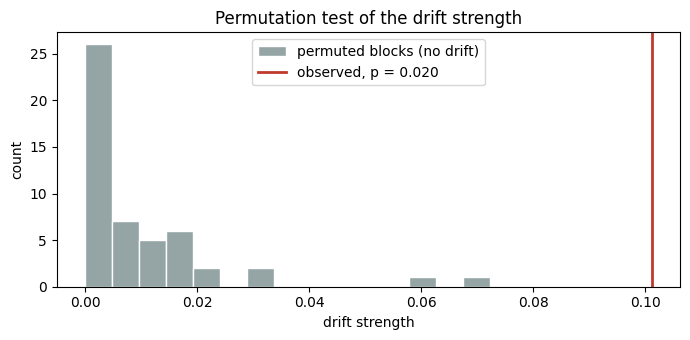

Triggered / evaluated checks per class and criterion:

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
False,False,1/2,1/18,2/2
True,False,0/3,1/27,0/3


Clusters (distances in standardised feature space; centroid shift threshold 0.26, spread change threshold 10%):

,class,n before,n after,status,centroid shift,spread before,spread after,spread change
cluster,,,,,,,,
0,False,155,210,tracked,0.219,1.004,1.114,+11.0%
1,False,146,221,tracked,0.303,0.922,1.126,+22.2%
2,True,244,217,tracked,0.153,1.066,1.010,-5.3%
3,True,247,194,tracked,0.235,1.056,0.987,-6.5%
4,True,208,158,tracked,0.181,1.059,1.001,-5.5%


Change of per-cluster statistics in standard deviations (bold: above `thr_desc_stats` = 0.2):

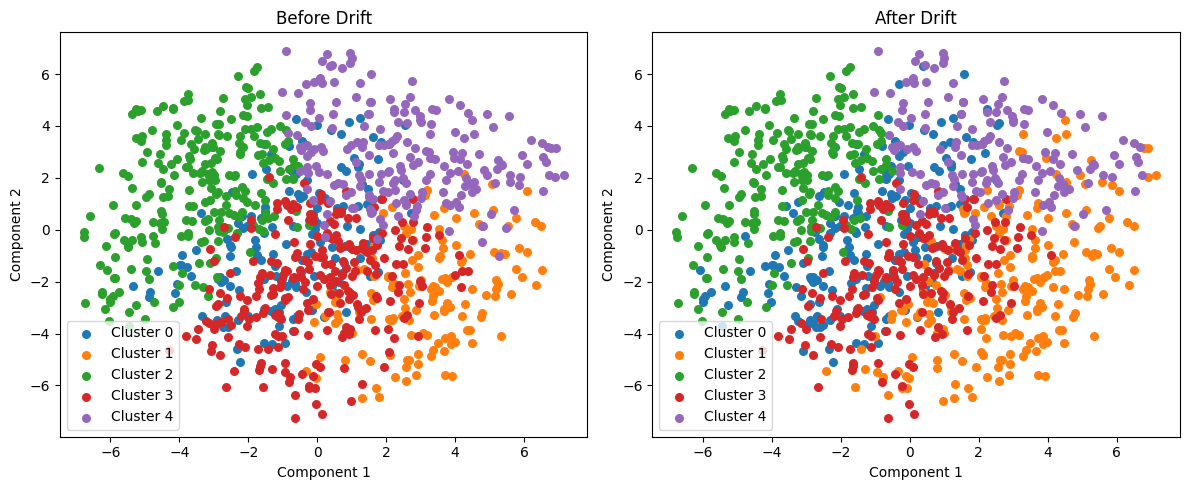

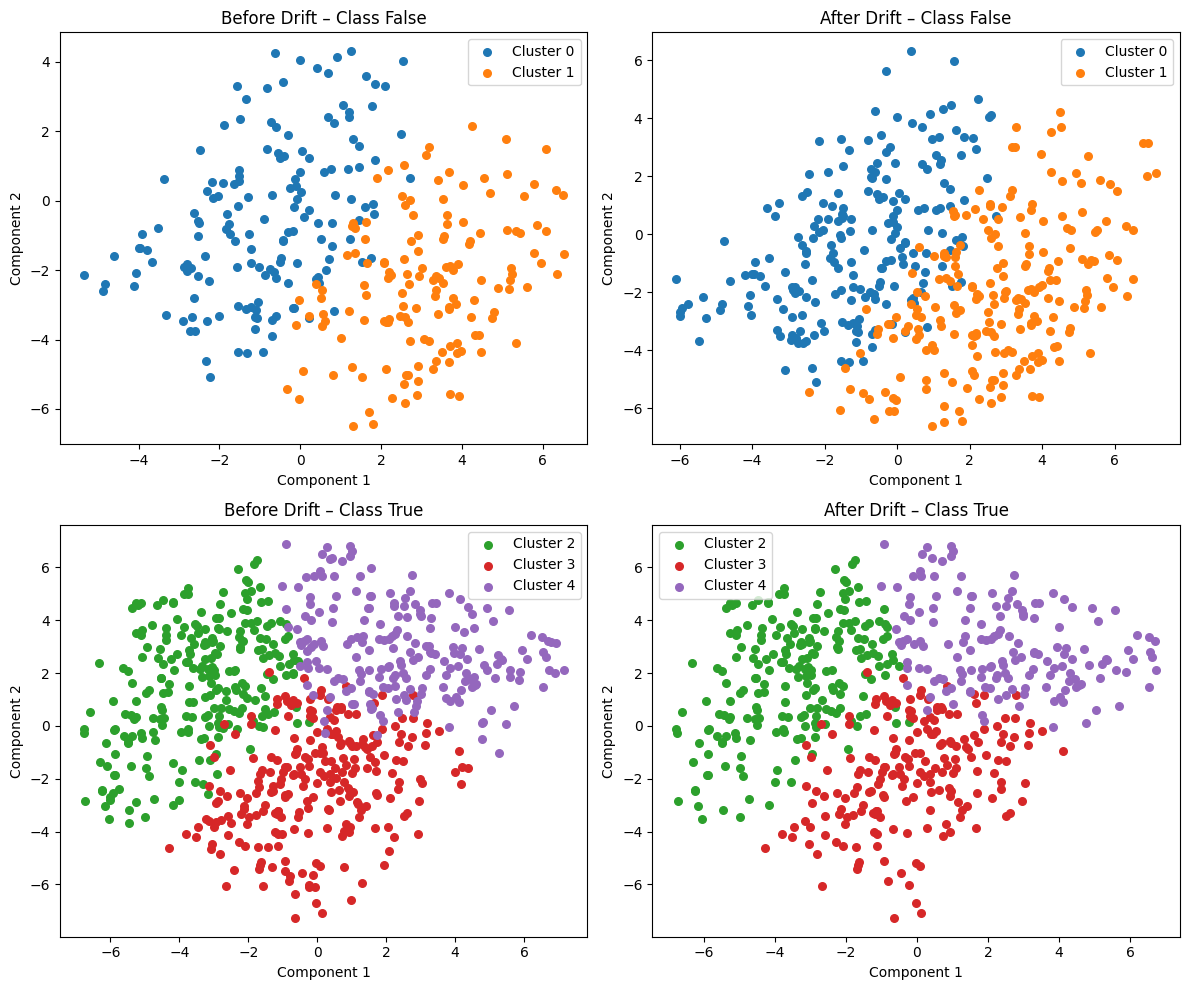

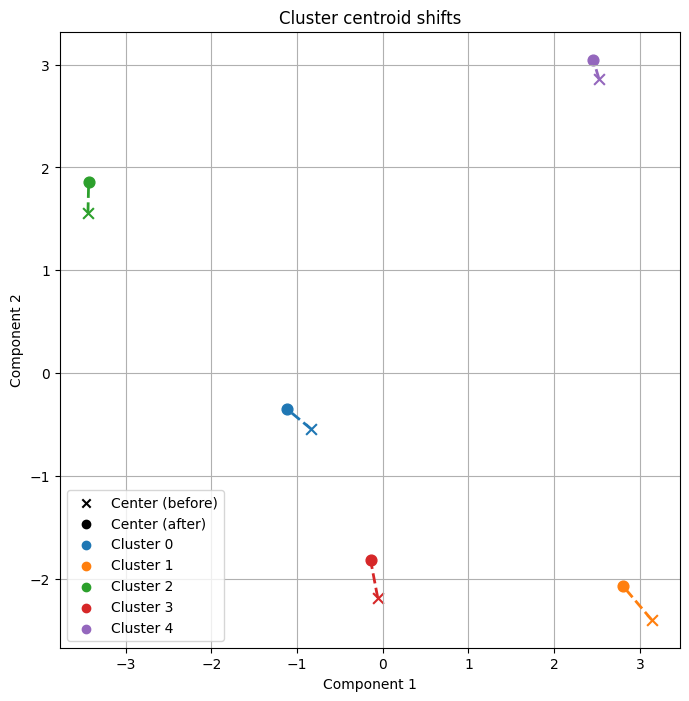

In [7]:
run_experiment(DatasetType.SEA)

**Analysis**

* **Descriptive statistics** flag drift: in class `False` the mean, median and standard deviation of `X1` and `X2` grow by about 20%, while `X3` does not change.
* **Statistical tests** do not reach the decision threshold: only Anderson–Darling flags `X1` and `X2`, and KS flags only `X1` of class `False`. JS and Wasserstein stay below their thresholds.
* **Clustering dynamics** detects drift. The cluster structure is unchanged: 5 clusters, none appeared or disappeared, all tracked.
  * The change is in class `False`: its two clusters became wider (spread +11% and +22%), and cluster 1 moved beyond the centroid threshold. Class `False` now covers a larger part of the `X1`–`X2` space.
  * `X3` changes by less than 0.04σ in every cluster, so it is correctly identified as unaffected.
  * The drift strength is small (0.10, far below the former fixed threshold of 0.5). It is still larger than every one of the 50 strengths obtained without drift (95th percentile 0.03). The permutation test therefore detects a drift that a fixed threshold would miss.

## 2. Hyperplane

**2 features, 1000 + 1000 samples.** Class counts before: {0: 462, 1: 538}, after: {0: 522, 1: 478}

#### Descriptive statistics — drift detected: **True**

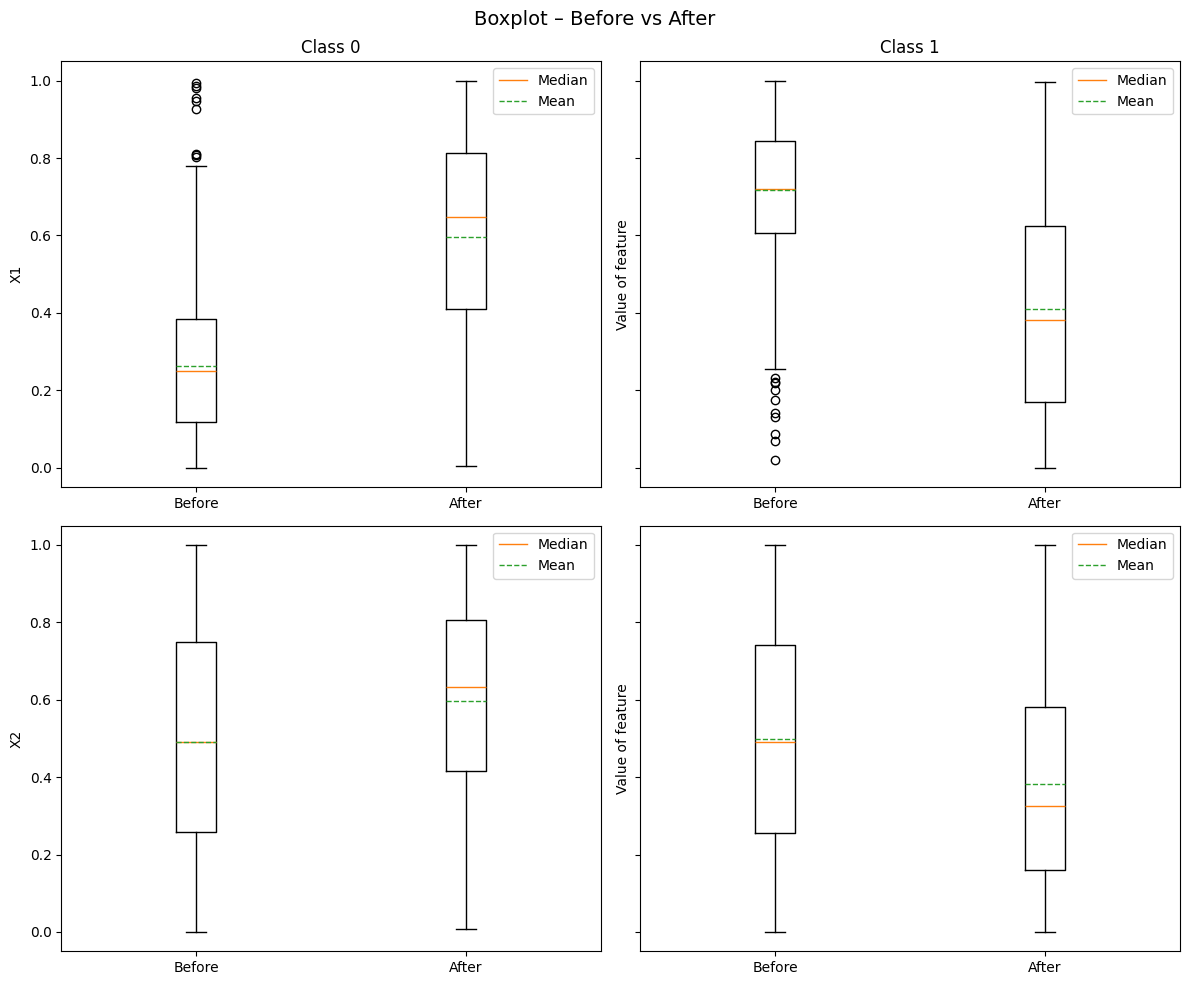

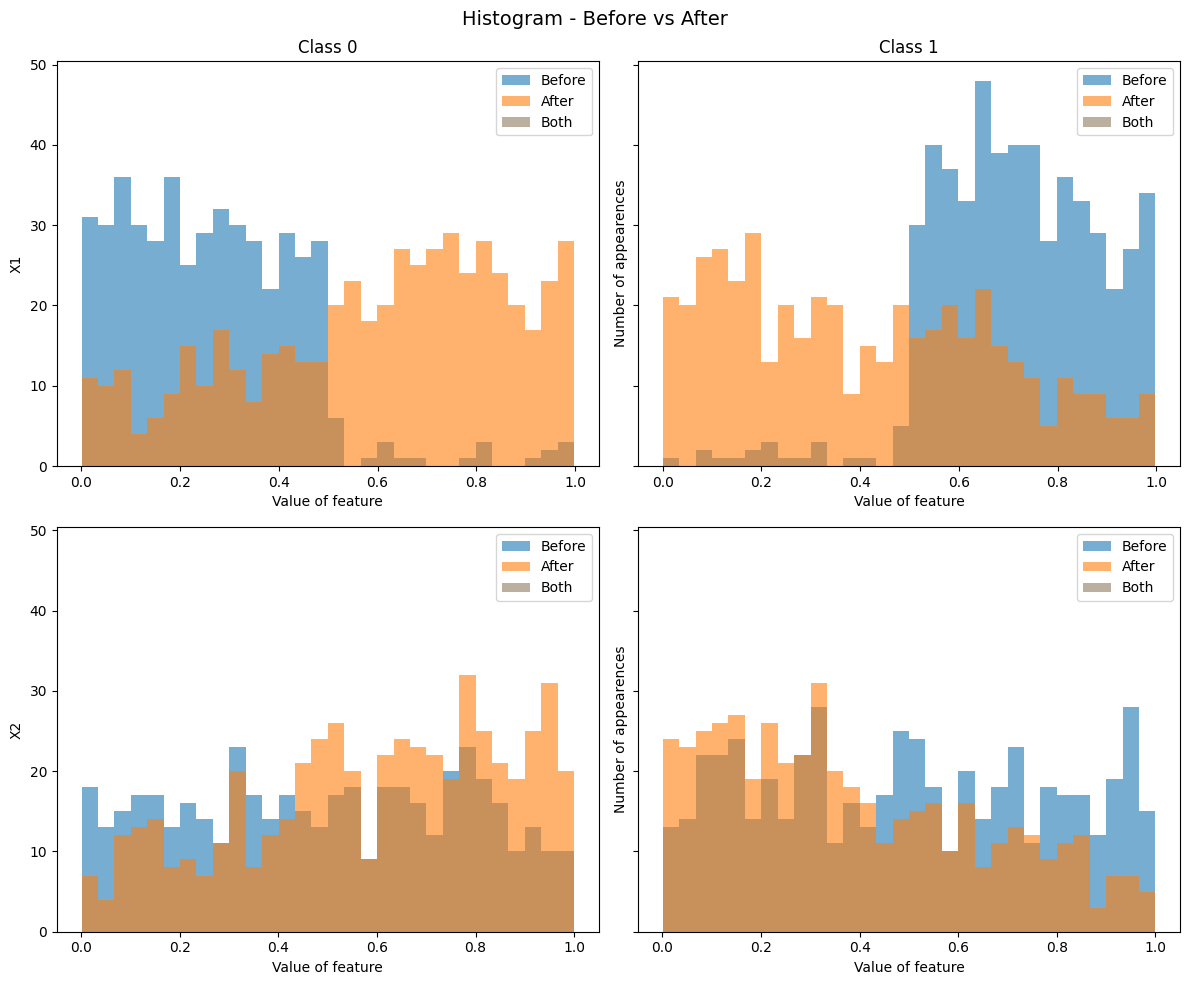

#### Statistical tests — drift detected: **True**

,kolmogorov_smirnov,anderson_darling,jensen_shannon,wasserstein
drift detected,True,True,True,True


KS p-value AD p-value JS divergence (thr 0.05)  \
class feature                                                  
0     X1         0.000 *    0.001 *                  0.266 *   
      X2         0.000 *    0.001 *                    0.028   
1     X1         0.000 *    0.001 *                  0.221 *   
      X2         0.000 *    0.001 *                    0.028   

              Wasserstein (thr 0.1)  
class feature                        
0     X1                    0.334 *  
      X2                    0.106 *  
1     X1                    0.307 *  
      X2                    0.115 *

#### Clustering dynamics — drift detected: **True**

Drift strength **0.558**, permutation p-value **0.020** (95th percentile of the strength without drift: 0.037). Clusters: 4 in the reference block, 7 in the detection block.

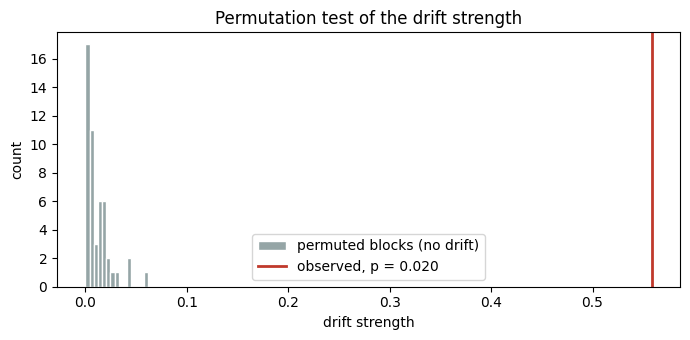

Triggered / evaluated checks per class and criterion:

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,True,0/1,1/6,0/1
1,True,1/2,2/12,1/2


Clusters (distances in standardised feature space; centroid shift threshold 0.21, spread change threshold 10%):

,class,n before,n after,status,centroid shift,spread before,spread after,spread change
cluster,,,,,,,,
0,0,231,137,tracked,0.069,0.692,0.762,+10.0%
1,0,231,0,disappeared,nan,0.722,nan,–
2,0,0,194,appeared,nan,nan,0.816,–
3,0,0,191,appeared,nan,nan,0.638,–
4,1,281,164,tracked,0.266,0.696,0.610,-12.2%
5,1,257,47,tracked,0.087,0.710,0.696,-2.0%
6,1,0,143,appeared,nan,nan,0.585,–
7,1,0,124,appeared,nan,nan,0.614,–


Change of per-cluster statistics in standard deviations (bold: above `thr_desc_stats` = 0.2):

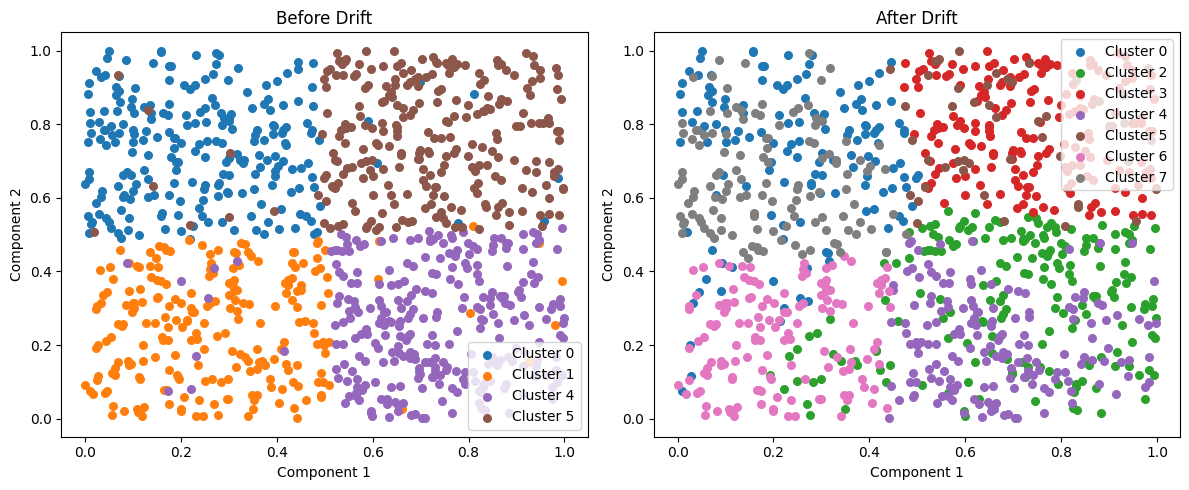

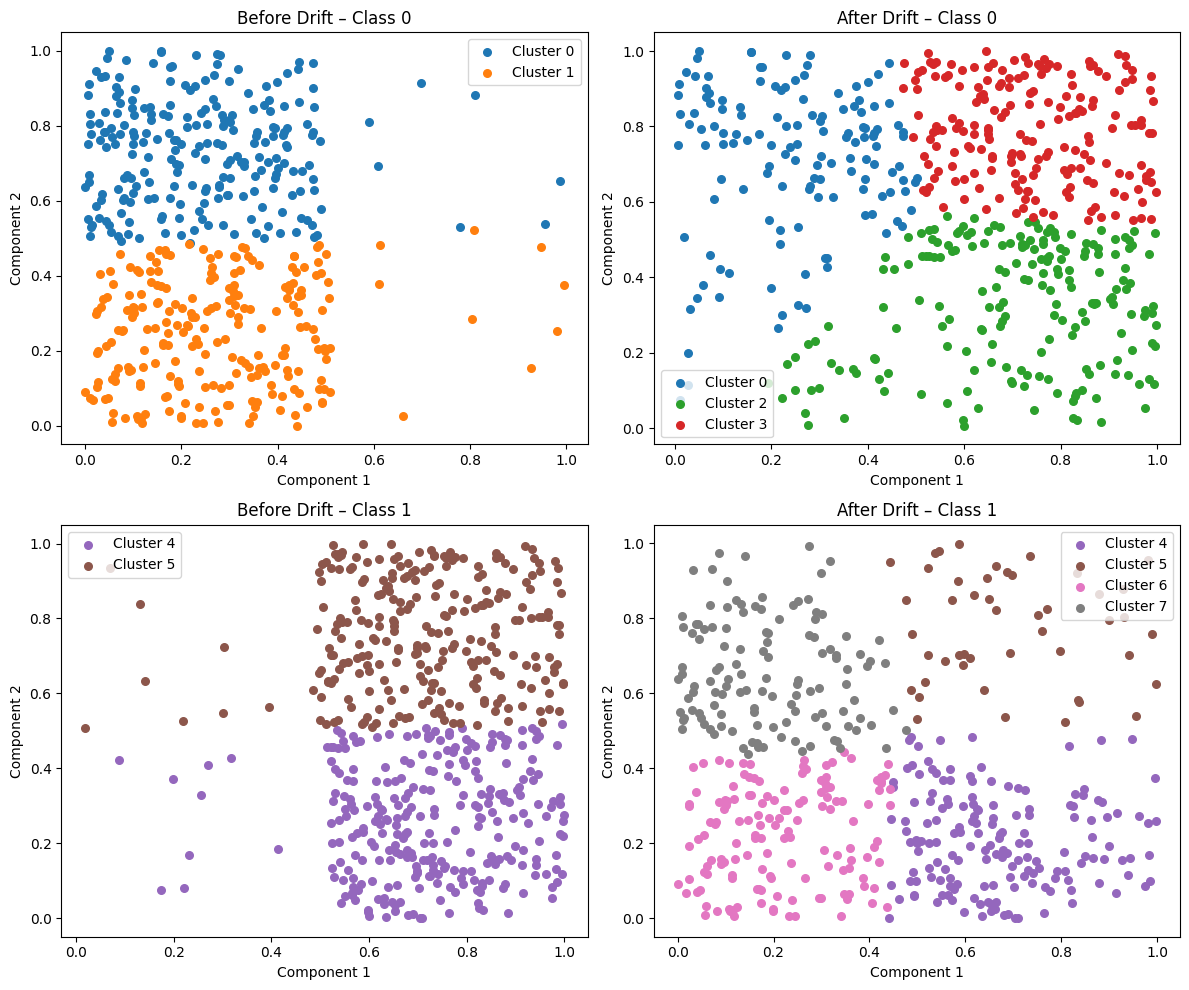

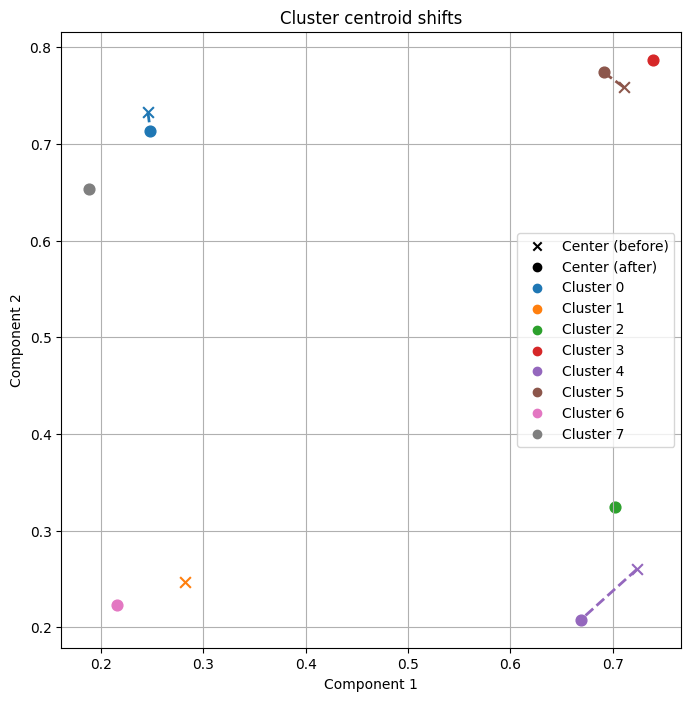

In [8]:
run_experiment(DatasetType.Hyperplane)

**Analysis**

* All three detectors flag drift. Both features of both classes change: KS p < 0.001, and the class means of `X1` move in opposite directions.
* **Clustering dynamics** explains *how* the classes moved. The reference block has 4 clusters: class 0 has the upper-left cluster 0 and the lower-left cluster 1; class 1 has the lower-right cluster 4 and the upper-right cluster 5. After the drift:
  * class 0 lost its lower-left mode: **cluster 1 disappeared** (231 → 0 samples);
  * class 0 now occupies the right half: **clusters 2 and 3 appeared**;
  * class 1 now occupies the left half: **clusters 6 and 7 appeared**, and its upper-right cluster 5 shrank from 257 to 47 samples.
  
  The decision boundary has rotated, which is exactly what a hyperplane drift does. The tracked clusters 0 and 5 barely moved (centroid shift < 0.1). The drift is structural, not a displacement of existing modes.
* Drift strength 0.56 against a 95th percentile of 0.04 without drift.

## 3. RBF

**4 features, 1000 + 1000 samples.** Class counts before: {0: 502, 1: 498}, after: {0: 503, 1: 497}

#### Descriptive statistics — drift detected: **False**

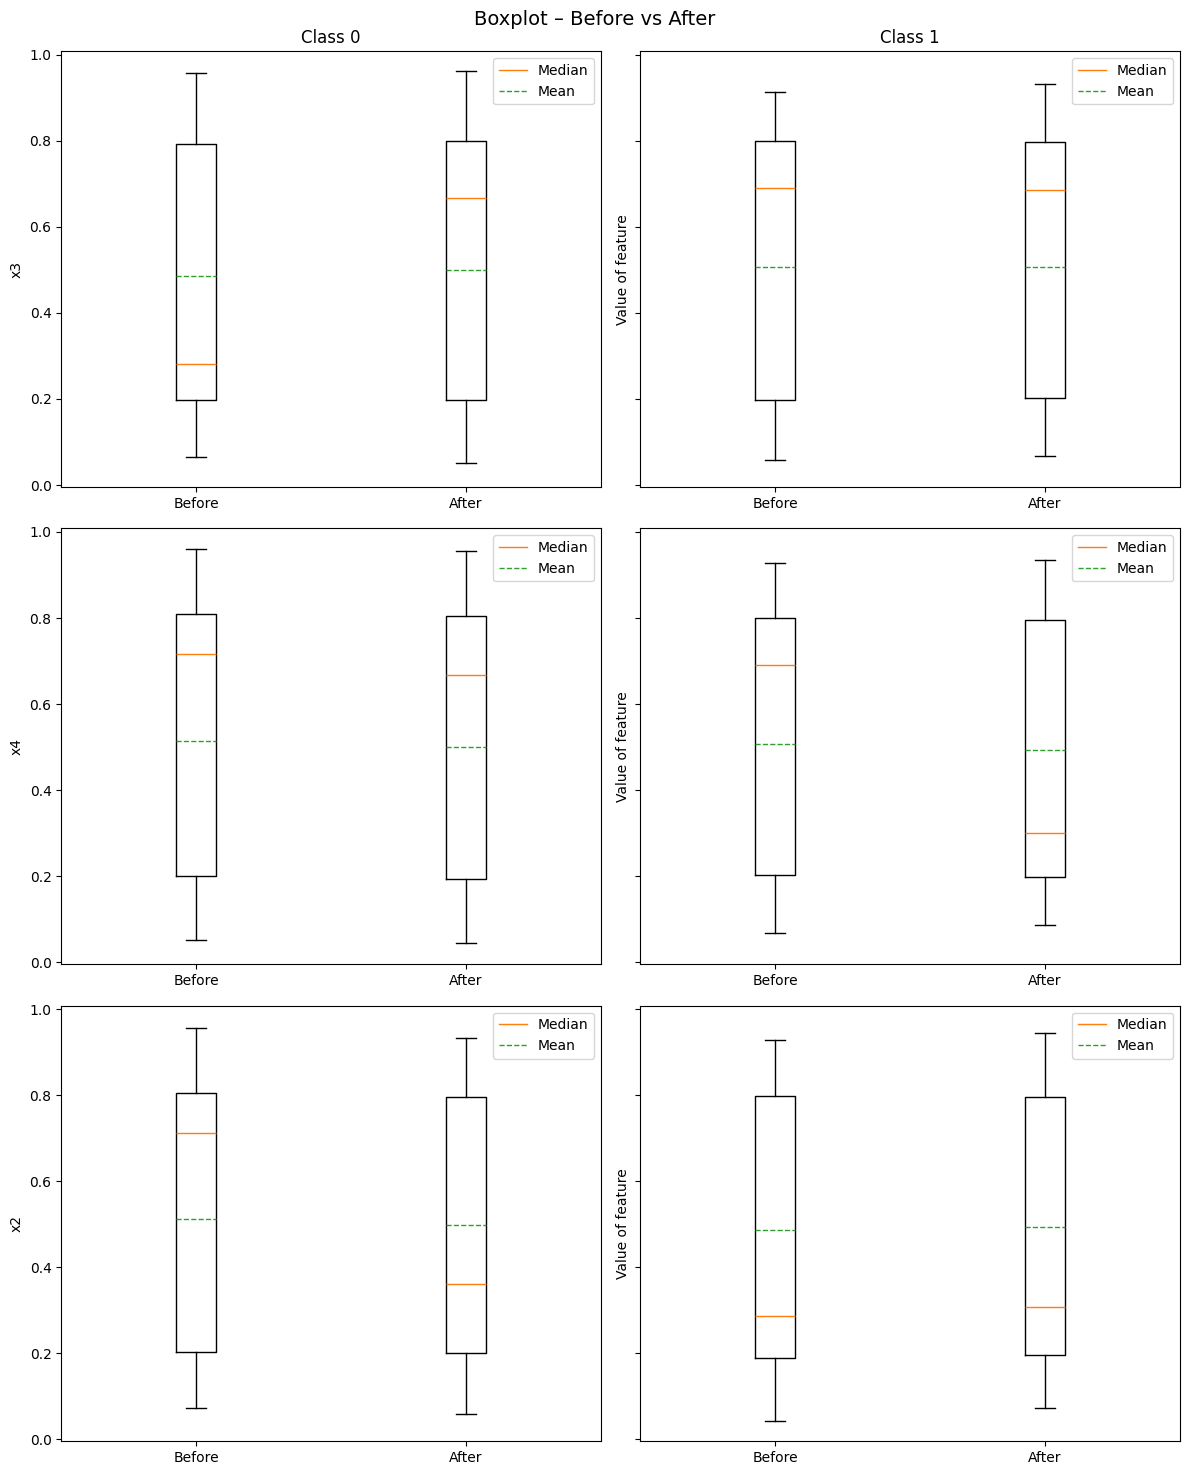

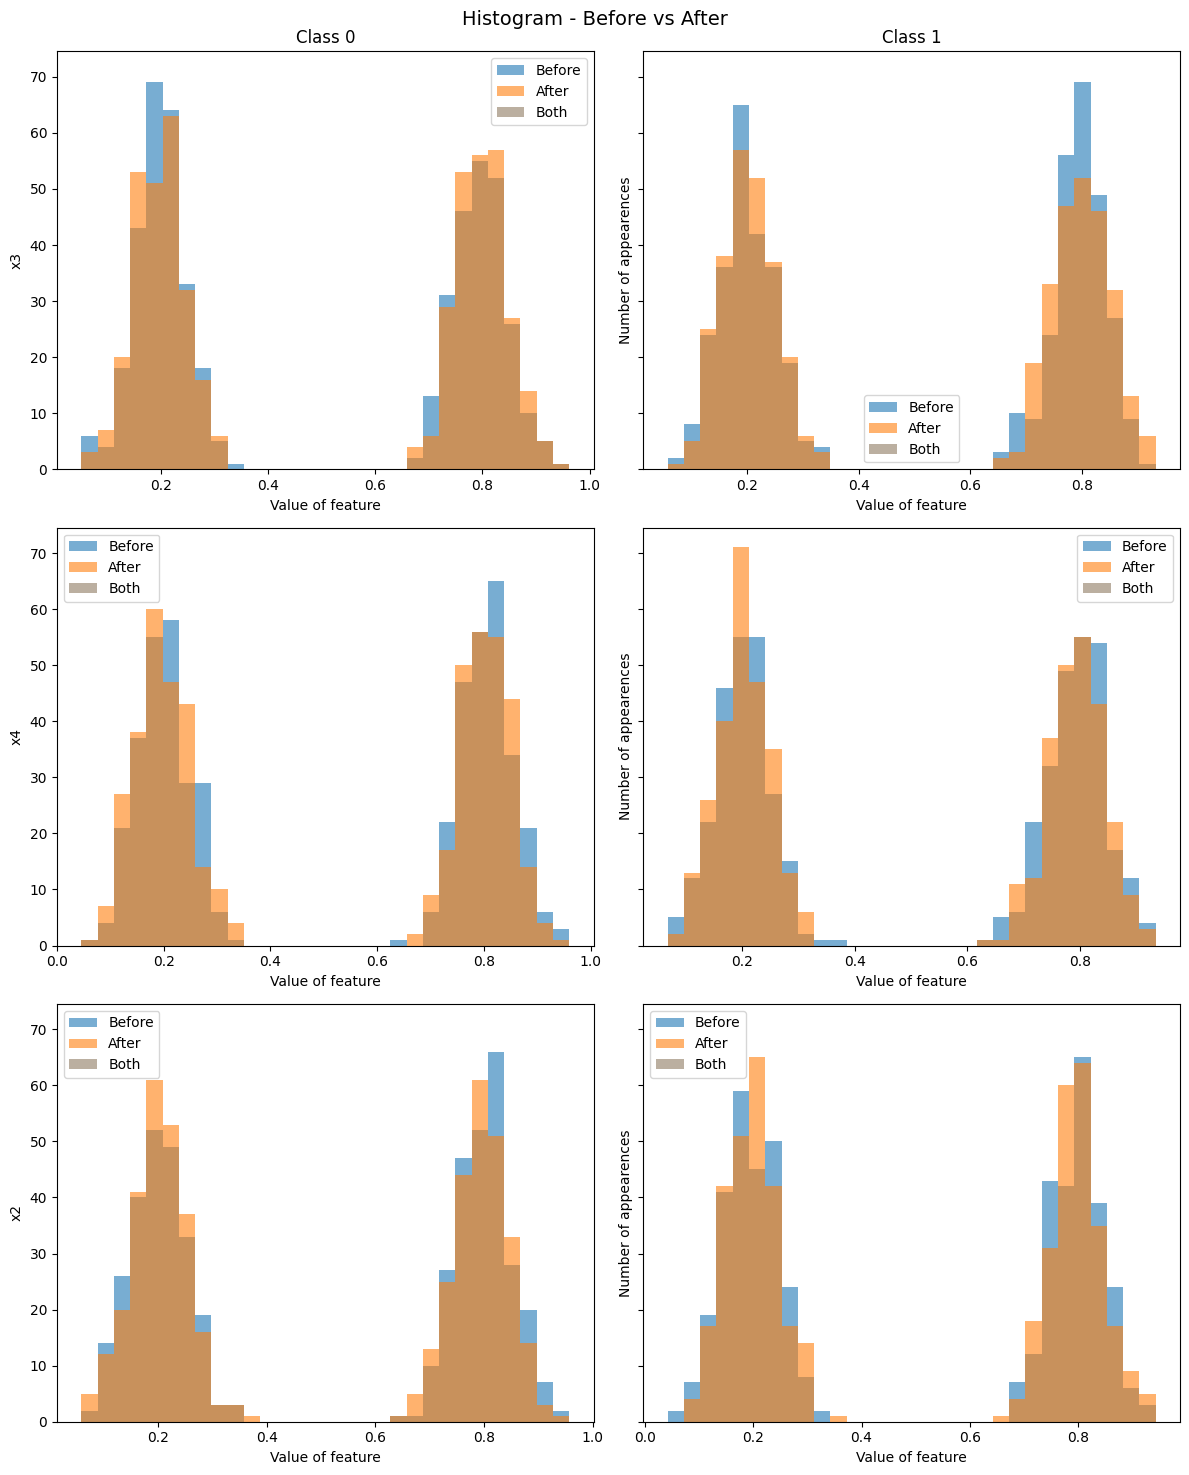

#### Statistical tests — drift detected: **False**

,kolmogorov_smirnov,anderson_darling,jensen_shannon,wasserstein
drift detected,False,False,False,False


KS p-value AD p-value JS divergence (thr 0.05)  \
class feature                                                  
0     x1           0.871      0.250                    0.011   
      x2           0.584      0.250                    0.011   
      x3           0.459      0.250                    0.011   
      x4           0.494      0.250                    0.008   
1     x1           0.590      0.250                    0.011   
      x2           0.925      0.250                    0.010   
      x3           0.813      0.250                    0.006   
      x4           0.964      0.250                    0.009   

              Wasserstein (thr 0.1)  
class feature                        
0     x1                      0.014  
      x2                      0.018  
      x3                      0.018  
      x4                      0.016  
1     x1                      0.021  
      x2                      0.008  
      x3                      0.009  
      x4                      0.016

#### Clustering dynamics — drift detected: **True**

Drift strength **1.000**, permutation p-value **0.020** (95th percentile of the strength without drift: 0.013). Clusters: 4 in the reference block, 4 in the detection block.

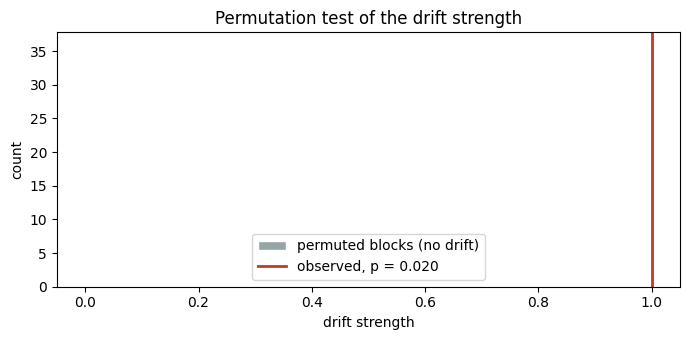

Triggered / evaluated checks per class and criterion:

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,True,0/0,0/0,0/0
1,True,0/0,0/0,0/0


Clusters (distances in standardised feature space; centroid shift threshold 0.30, spread change threshold 10%):

,class,n before,n after,status,centroid shift,spread before,spread after,spread change
cluster,,,,,,,,
0,0,261,0,disappeared,nan,0.301,nan,–
1,0,241,0,disappeared,nan,0.315,nan,–
2,0,0,251,appeared,nan,nan,0.310,–
3,0,0,252,appeared,nan,nan,0.307,–
4,1,257,0,disappeared,nan,0.315,nan,–
5,1,241,0,disappeared,nan,0.312,nan,–
6,1,0,253,appeared,nan,nan,0.306,–
7,1,0,244,appeared,nan,nan,0.303,–


No cluster is present in both blocks, so per-cluster statistics are not compared.

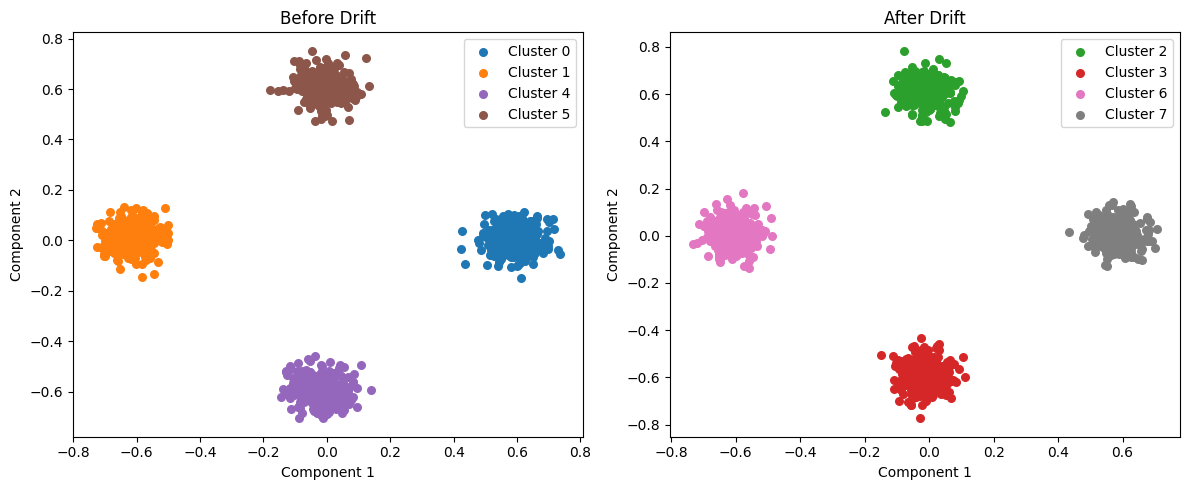

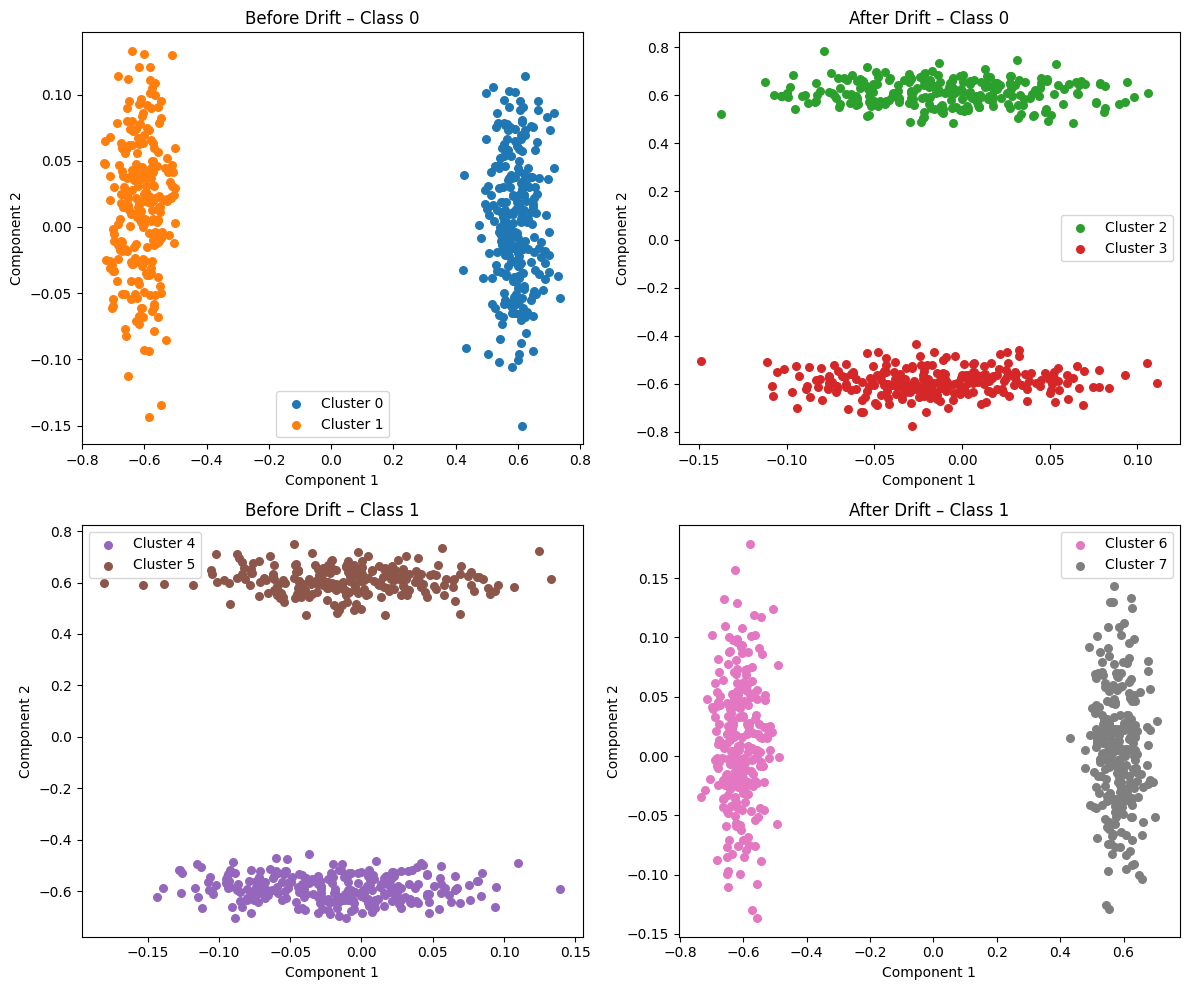

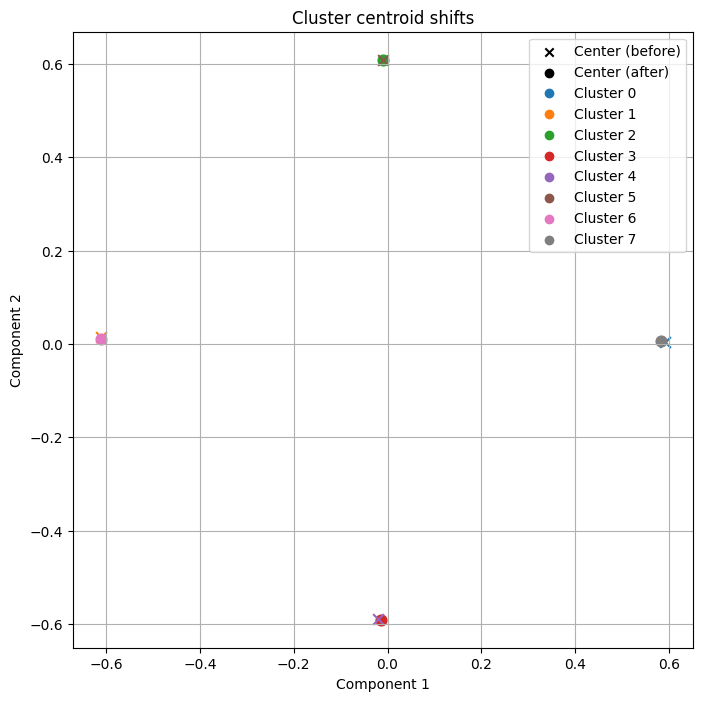

In [9]:
run_experiment(DatasetType.RBF)

**Analysis**

In this dataset the drift **swaps the class assignment of the RBF clusters**: the regions that belonged to class 0 now belong to class 1 and vice versa.

* **Descriptive statistics** and **statistical tests** detect nothing. Each class is still a mixture of two well-separated blobs with the same per-feature marginals, so the class-wise means, standard deviations and per-feature distributions do not change (all KS p-values > 0.45).
* The medians do jump by up to ±137%. Every feature is bimodal within a class, so the median lies between the modes and is unstable. The relative change also inflates differences of values close to 0. These are artefacts, not signals.
* **Clustering dynamics** captures the change completely:
  * all four reference clusters disappeared and four new ones appeared, two per class;
  * every evaluated check is triggered, so the drift strength is 1.0;
  * the per-class plots show that each class now occupies the regions previously held by the other class.

The change is in the joint, multi-modal structure of the classes, not in any single feature. This is the case the clustering detector is designed for.

## 4. Linear Weight Inversion (LWI)

**11 features, 1000 + 1000 samples.** Class counts before: {0: 522, 1: 478}, after: {0: 484, 1: 516}

#### Descriptive statistics — drift detected: **True**

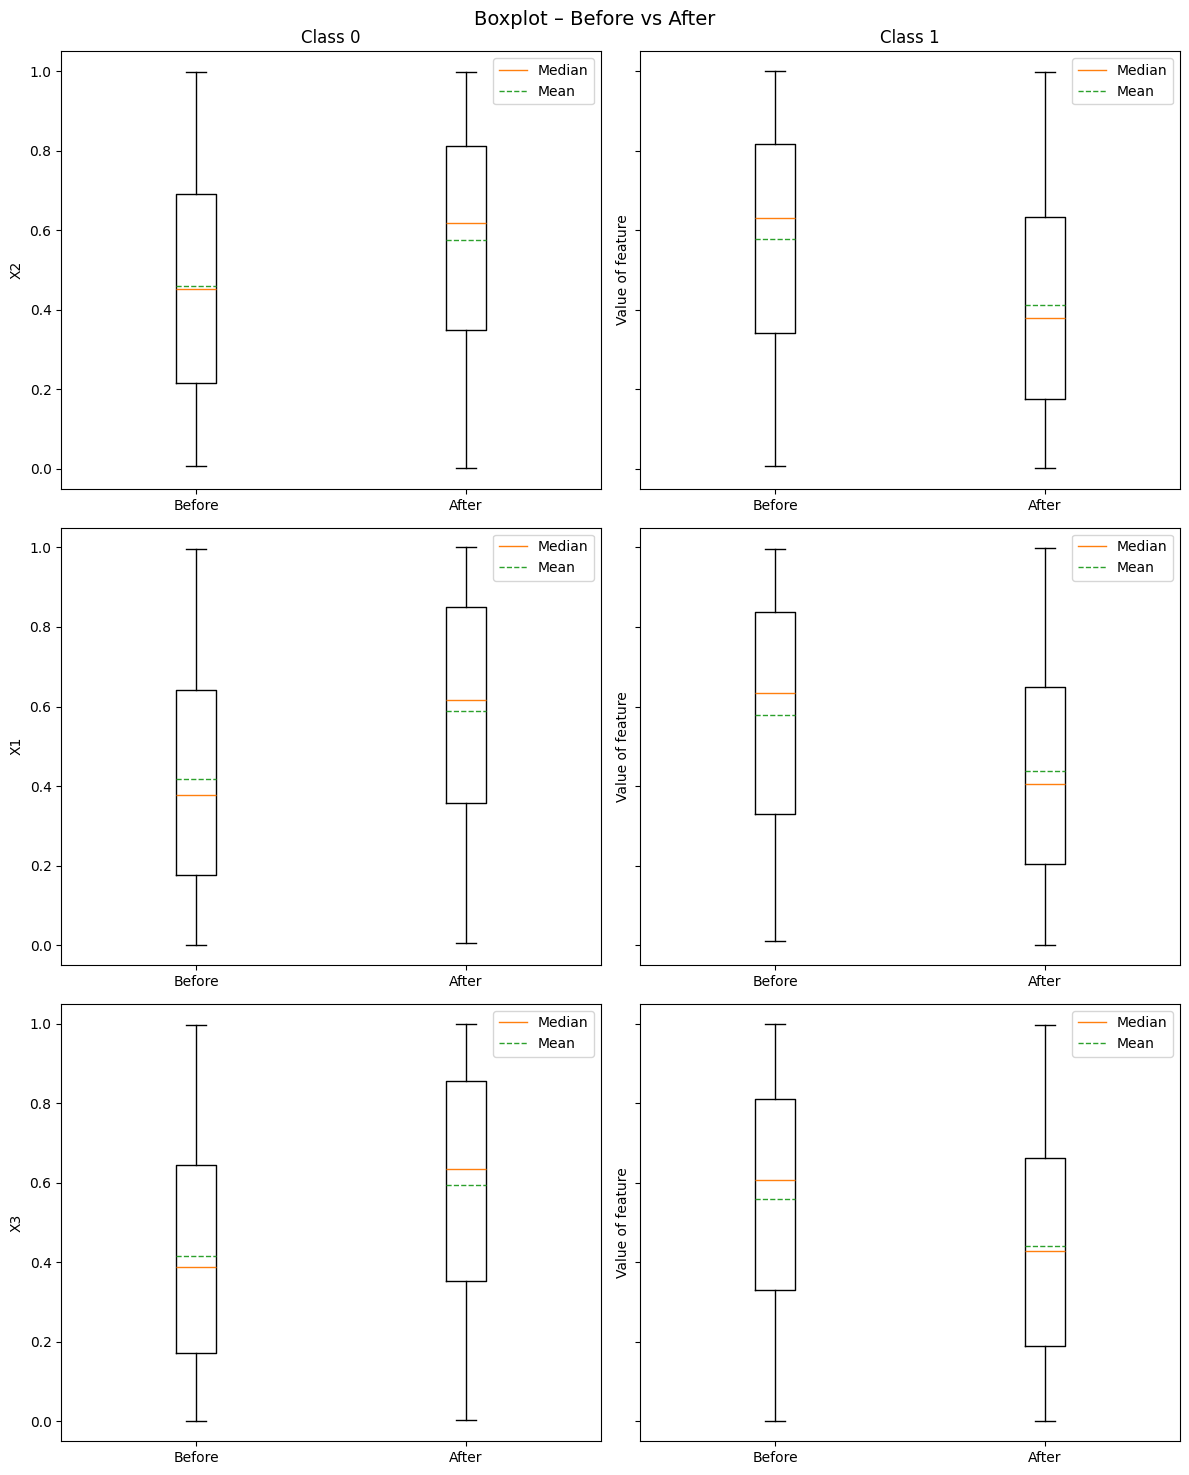

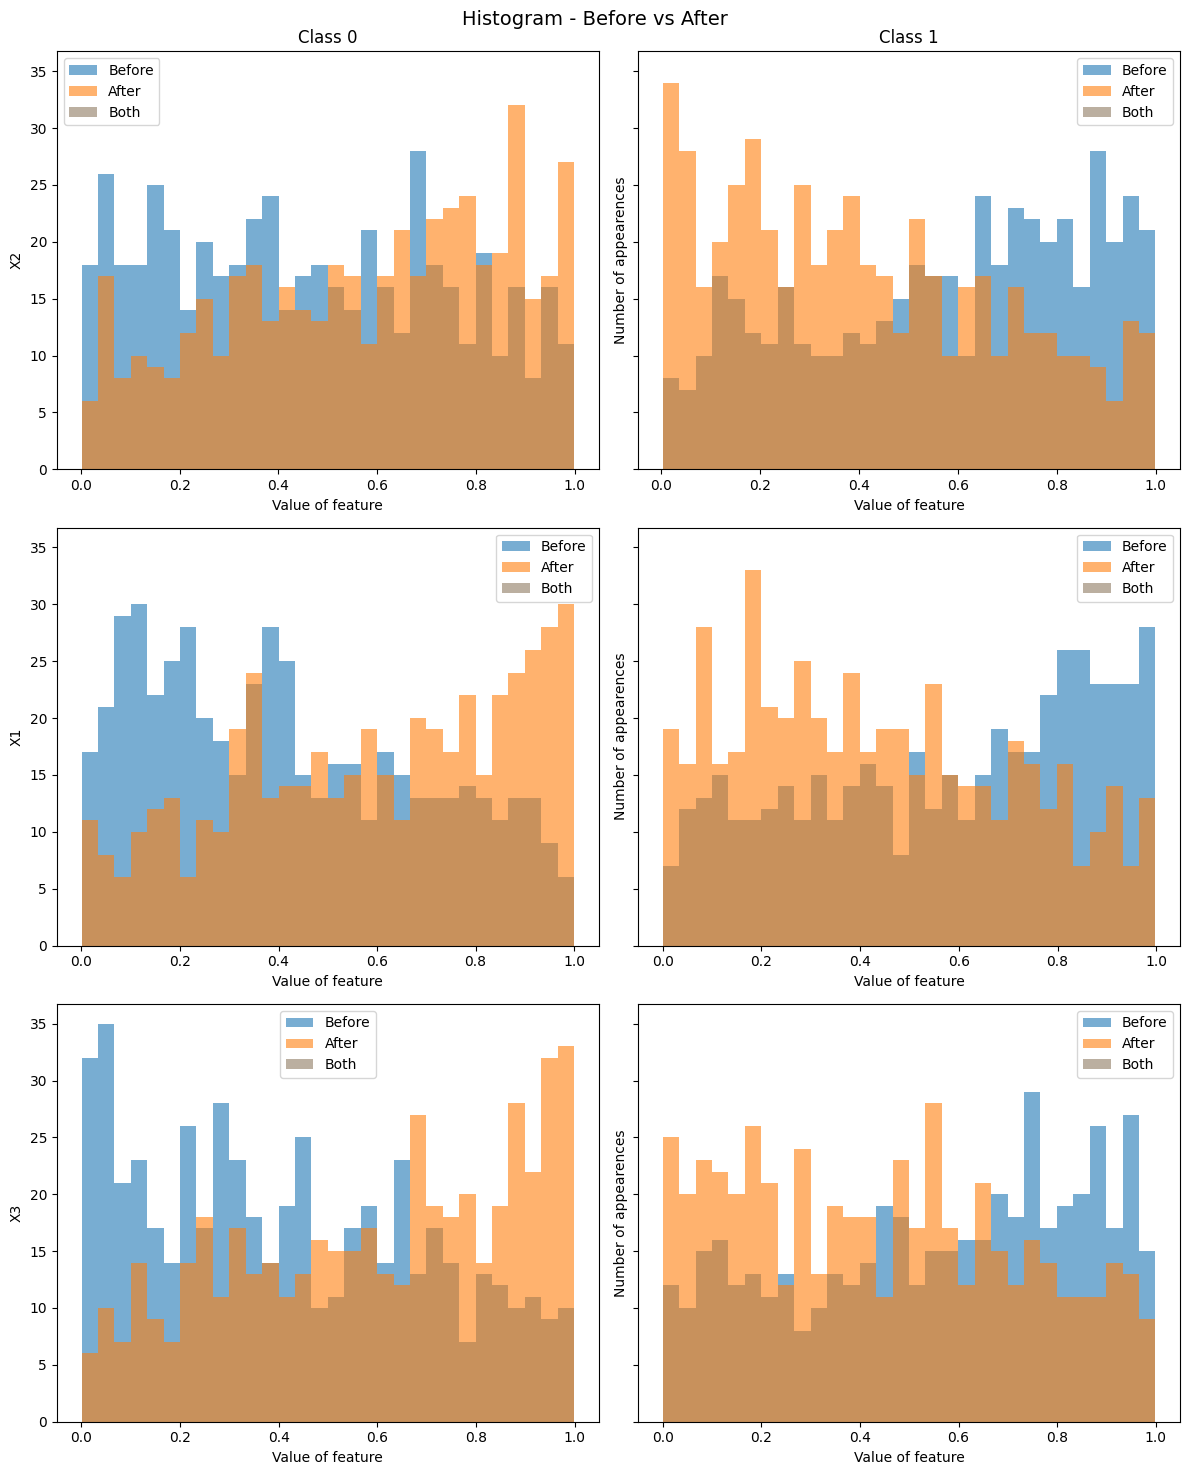

#### Statistical tests — drift detected: **True**

,kolmogorov_smirnov,anderson_darling,jensen_shannon,wasserstein
drift detected,True,True,False,True


KS p-value AD p-value JS divergence (thr 0.05)  \
class feature                                                  
0     X1         0.000 *    0.001 *                  0.057 *   
      X2         0.000 *    0.001 *                    0.040   
      X3         0.000 *    0.001 *                  0.061 *   
      X4         0.000 *    0.001 *                    0.048   
      X5         0.000 *    0.001 *                    0.042   
      X6         0.013 *    0.005 *                    0.021   
      X7           0.749      0.250                    0.013   
      X8           0.671      0.250                    0.010   
      X9           0.269      0.250                    0.014   
      X10          0.384      0.250                    0.023   
      X11          0.778      0.250                    0.017   
1     X1         0.000 *    0.001 *                    0.044   
      X2         0.000 *    0.001 *                    0.049   
      X3         0.000 *    0.001 *                    0.032   
      X4         0.000 *    0.001 *                    0.046   
      X5         0.000 *    0.001 *                    0.036   
      X6           0.854      0.250                    0.008   
      X7           0.344      0.250                    0.013   
      X8           0.772      0.250                    0.018   
      X9           0.695      0.250                    0.010   
      X10          0.219      0.179                    0.015   
      X11          0.569      0.250                    0.020   

              Wasserstein (thr 0.1)  
class feature                        
0     X1                    0.172 *  
      X2                    0.116 *  
      X3                    0.178 *  
      X4                    0.147 *  
      X5                    0.133 *  
      X6                      0.052  
      X7                      0.015  
      X8                      0.013  
      X9                      0.018  
      X10                     0.018  
      X11                     0.010  
1     X1                    0.143 *  
      X2                    0.167 *  
      X3                    0.118 *  
      X4                    0.144 *  
      X5                    0.126 *  
      X6                      0.009  
      X7                      0.018  
      X8                      0.011  
      X9                      0.020  
      X10                     0.028  
      X11                     0.013

#### Clustering dynamics — drift detected: **True**

Drift strength **0.337**, permutation p-value **0.020** (95th percentile of the strength without drift: 0.021). Clusters: 4 in the reference block, 4 in the detection block.

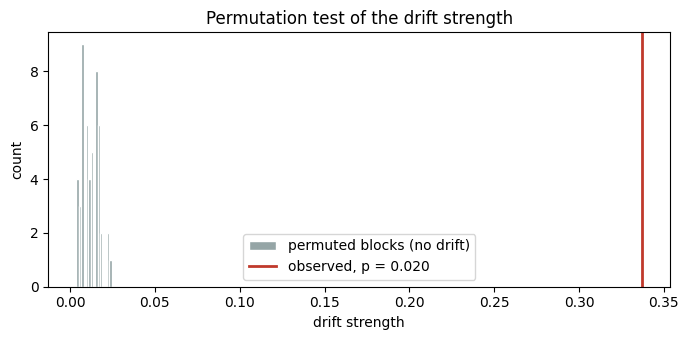

Triggered / evaluated checks per class and criterion:

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,False,2/2,24/66,0/2
1,False,2/2,22/66,0/2


Clusters (distances in standardised feature space; centroid shift threshold 0.50, spread change threshold 10%):

,class,n before,n after,status,centroid shift,spread before,spread after,spread change
cluster,,,,,,,,
0,0,249,188,tracked,1.359,3.033,3.100,+2.2%
1,0,273,296,tracked,1.050,3.056,3.135,+2.6%
2,1,260,310,tracked,1.045,3.105,3.120,+0.5%
3,1,218,206,tracked,1.194,3.032,3.010,-0.7%


Change of per-cluster statistics in standard deviations (bold: above `thr_desc_stats` = 0.2):

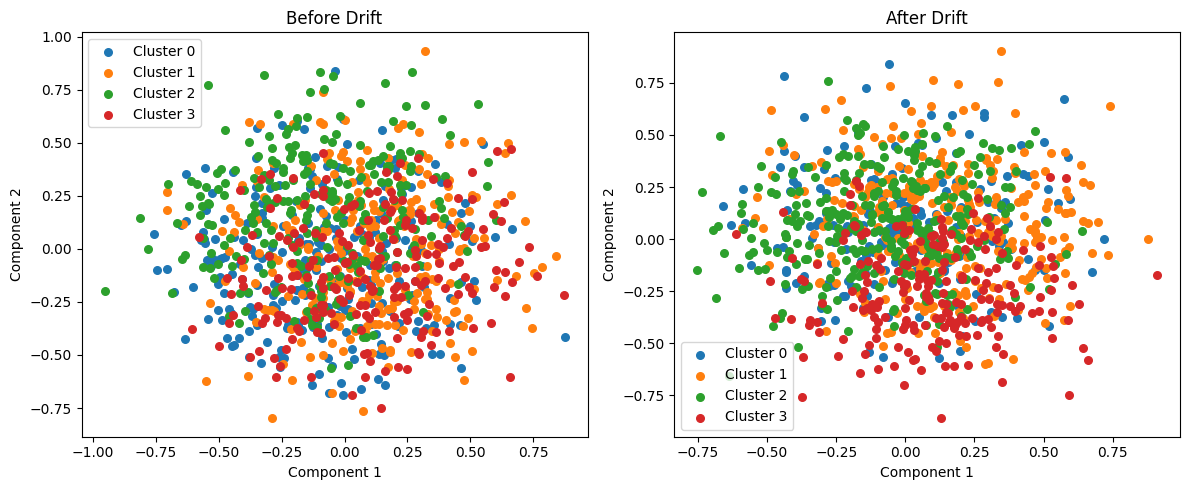

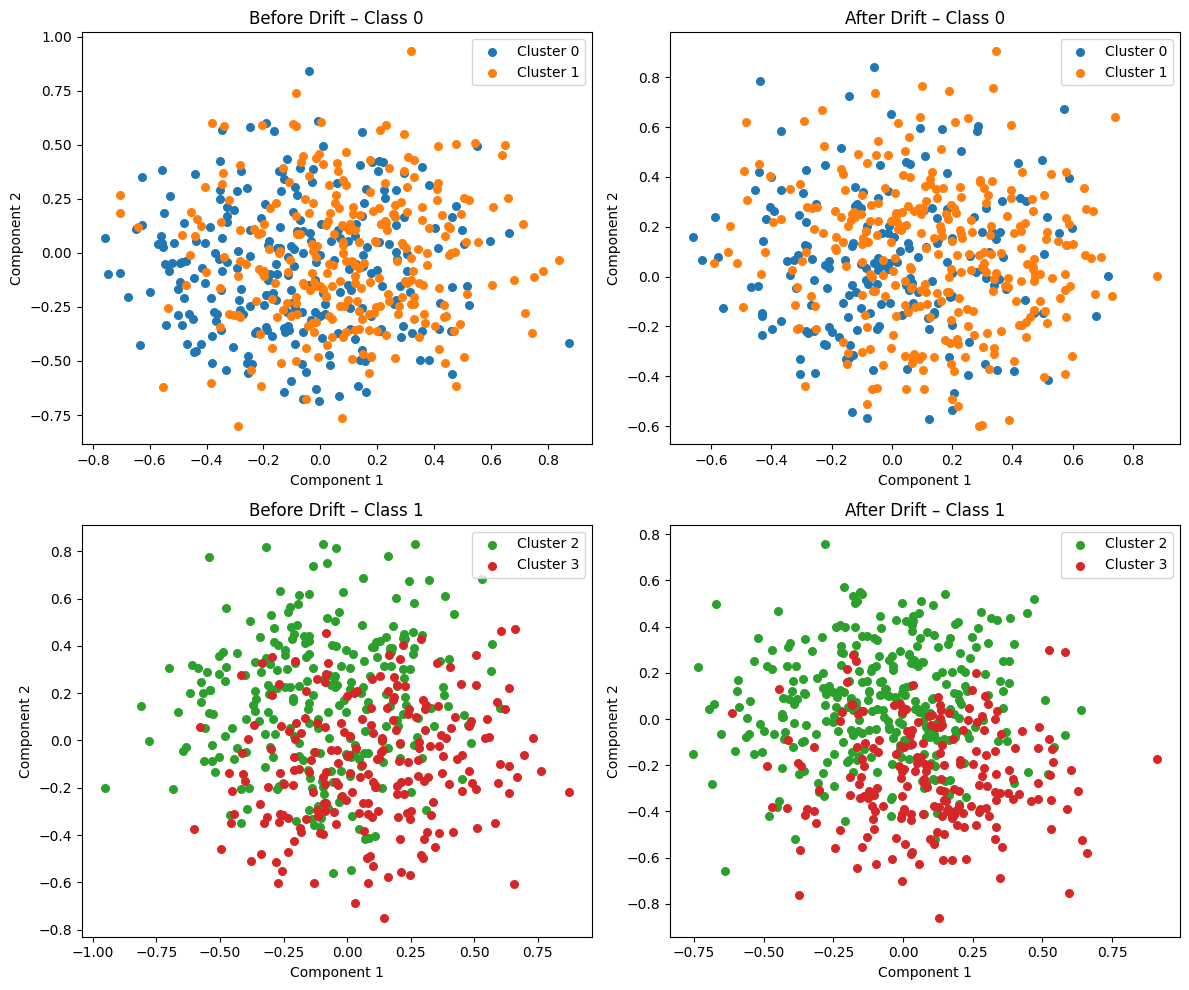

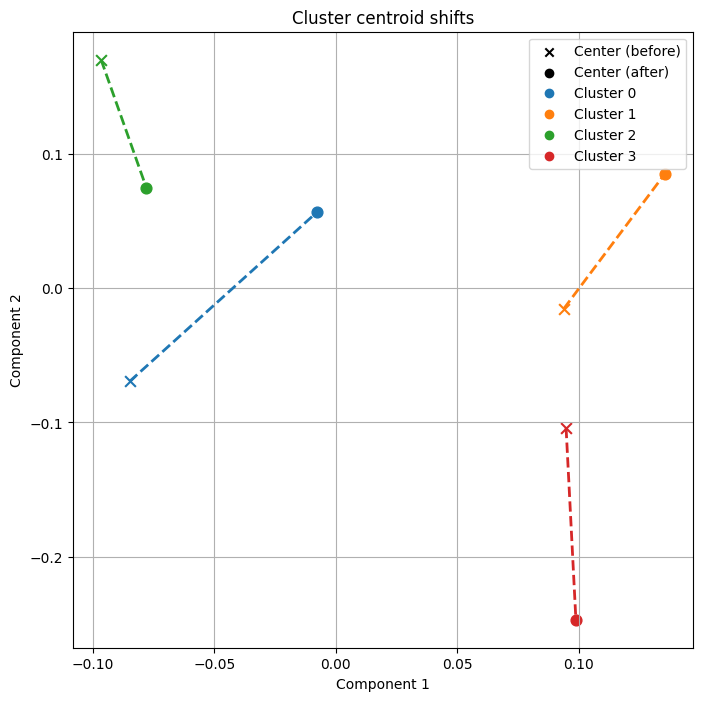

In [10]:
run_experiment(DatasetType.LWI)

**Analysis**

* All three detectors flag drift. The tests show that only **`X1`–`X5`** change: KS p < 0.001 in both classes, while `X7`–`X11` have p > 0.2. Class 0 moves up on these features and class 1 moves down, as the inverted weights prescribe.
* **Clustering dynamics**:
  * The cluster structure is stable (4 clusters, no appearance or disappearance, all tracked).
  * All four centroids shifted, by 1.05–1.36 against a threshold of 0.50 in 11 dimensions.
  * The spread is unchanged (±3%): the clusters moved without deforming.
  * The per-cluster statistics localise the drift. The mean and median shifts above 0.2σ concentrate on `X1`–`X5` (about 0.4–1.1σ, positive for class-0 clusters and negative for class-1 clusters). The remaining features mostly stay within the threshold, apart from a few medians at 0.25–0.32σ, which is sampling noise of the median.
* Drift strength 0.34 against a 95th percentile of 0.02 without drift.

## 5. Random Tree, multi-window

Window 0 (first concept) against window 10 (first window after the drift at sample 10 000).

**6 features, 1000 + 1000 samples.** Class counts before: {0: 267, 1: 733}, after: {0: 725, 1: 275}

#### Descriptive statistics — drift detected: **True**

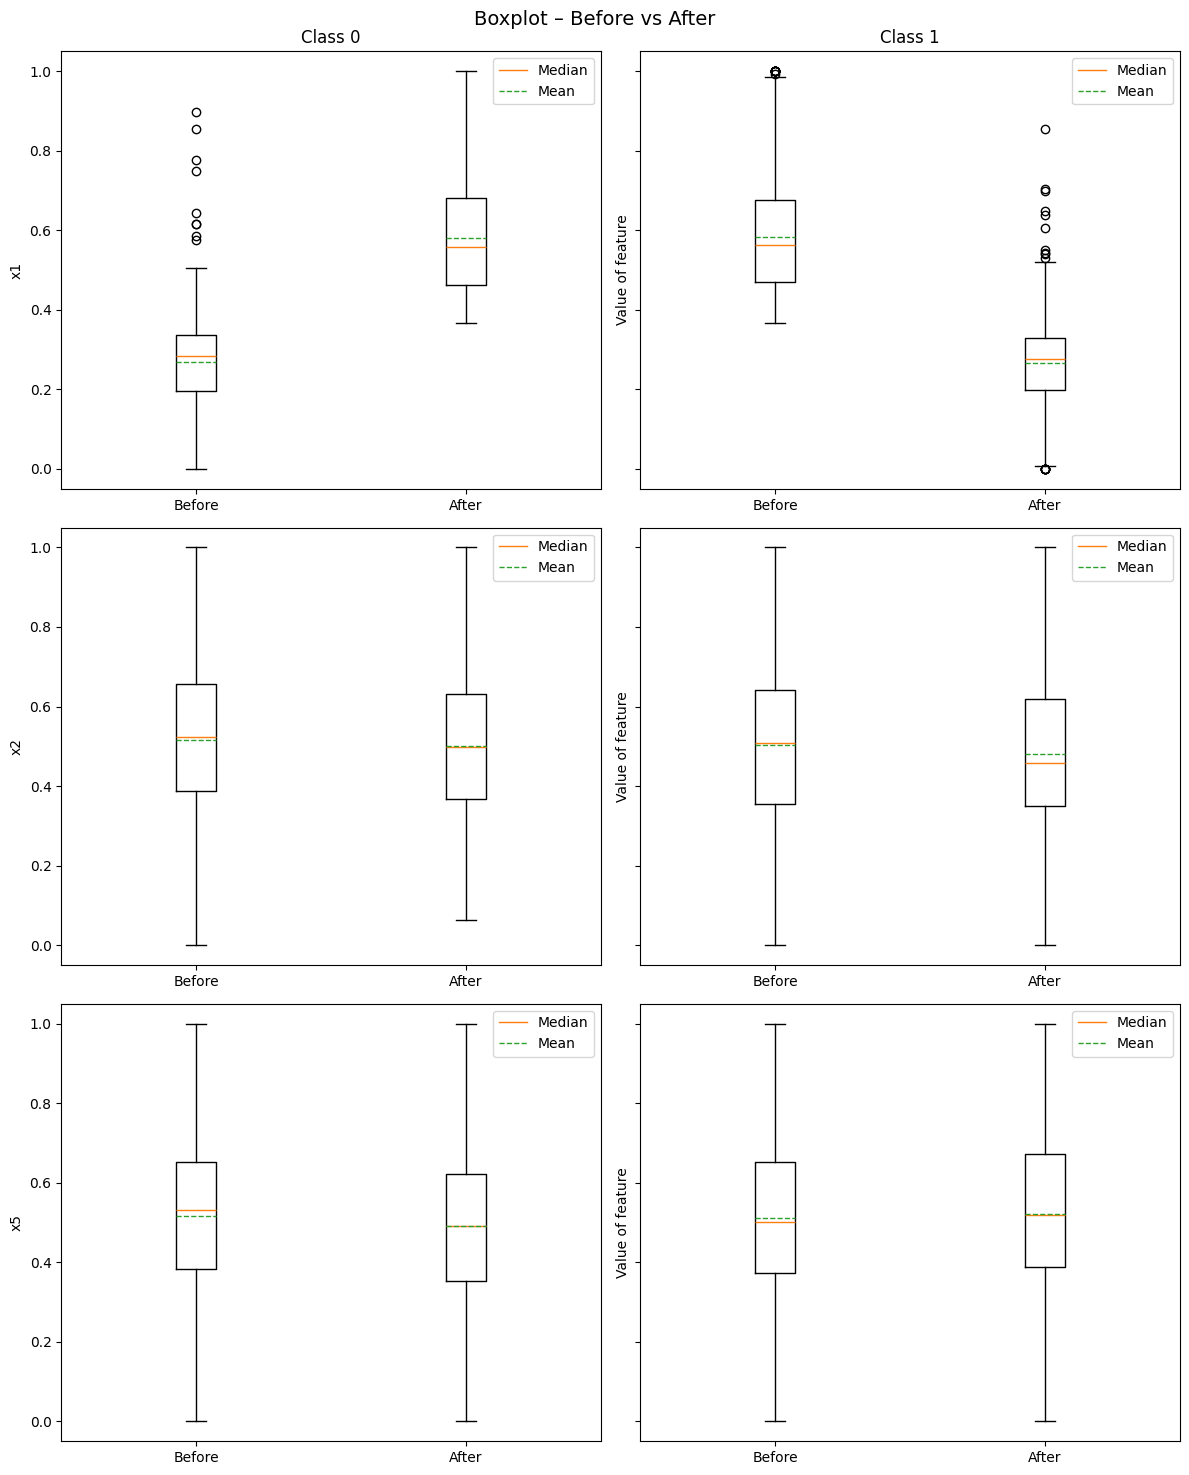

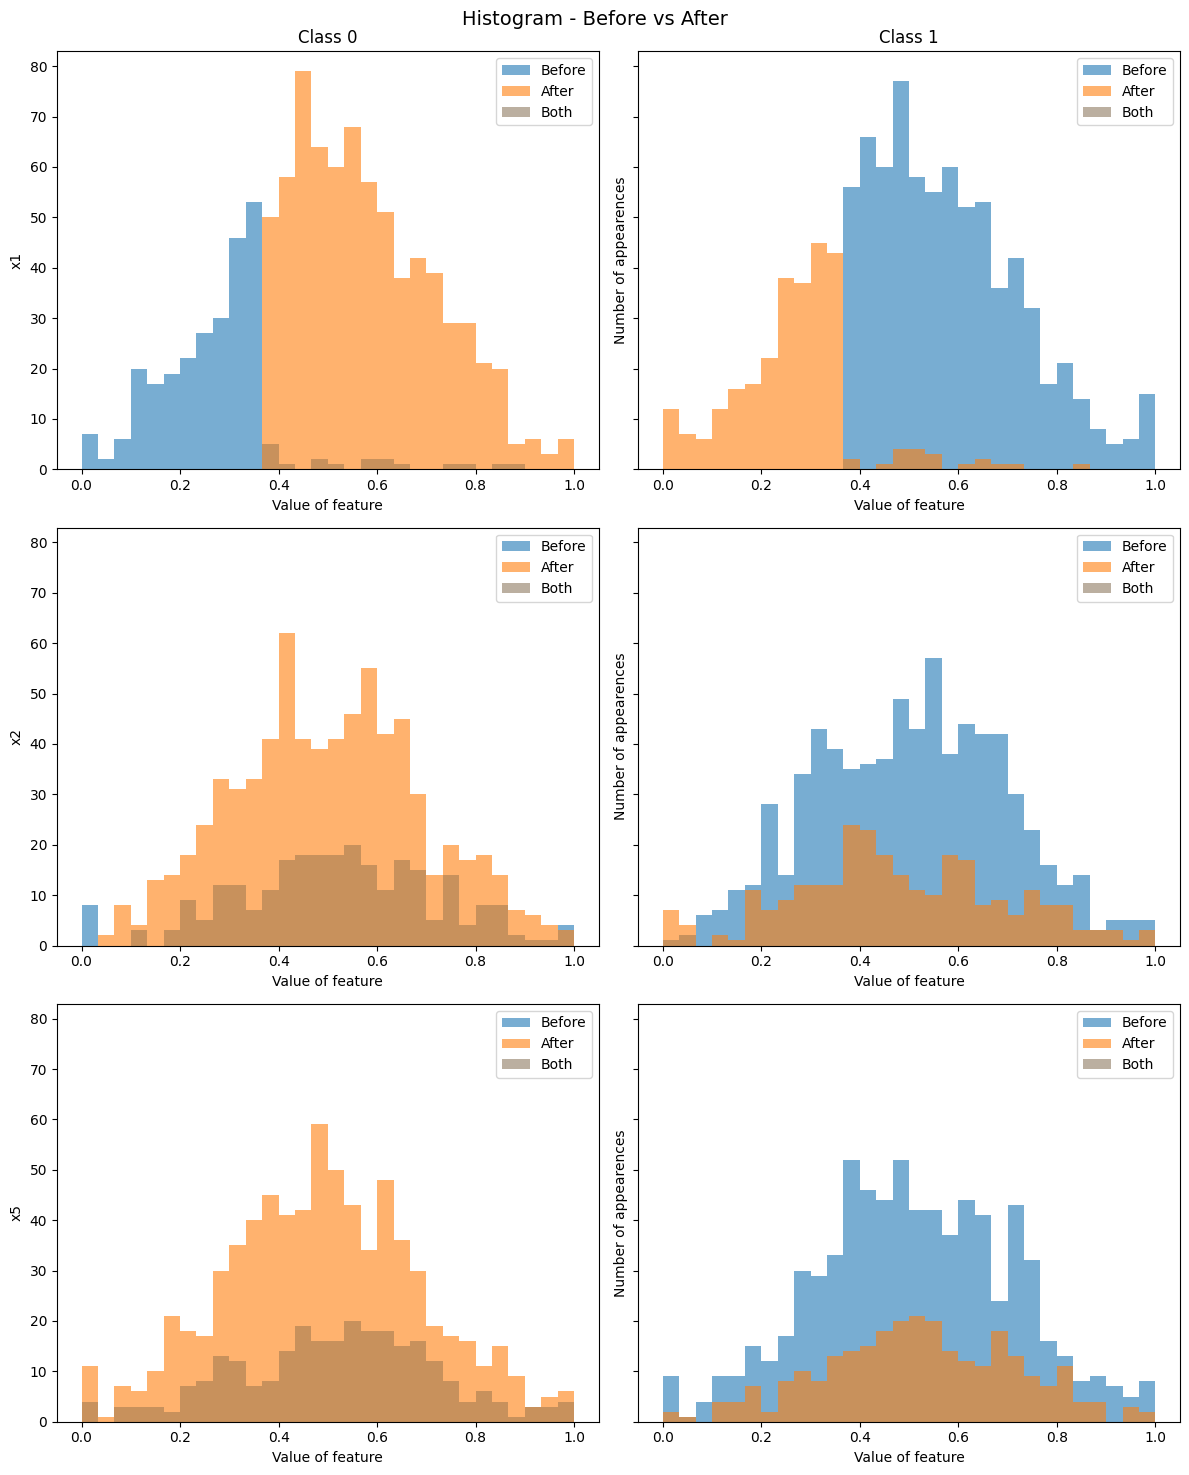

#### Statistical tests — drift detected: **True**

,kolmogorov_smirnov,anderson_darling,jensen_shannon,wasserstein
drift detected,True,True,False,False


KS p-value AD p-value JS divergence (thr 0.05)  \
class feature                                                  
0     x0           0.282    0.035 *                    0.031   
      x1         0.000 *    0.001 *                  0.572 *   
      x2           0.142      0.137                    0.035   
      x3           0.673      0.250                    0.018   
      x4           0.961      0.250                    0.020   
      x5         0.033 *    0.042 *                    0.019   
1     x0           0.123    0.019 *                    0.018   
      x1         0.000 *    0.001 *                  0.168 *   
      x2         0.029 *    0.049 *                    0.039   
      x3           0.904      0.250                    0.012   
      x4           0.528      0.250                    0.023   
      x5           0.452      0.250                    0.017   

              Wasserstein (thr 0.1)  
class feature                        
0     x0                      0.028  
      x1                    0.312 *  
      x2                      0.024  
      x3                      0.015  
      x4                      0.009  
      x5                      0.028  
1     x0                      0.035  
      x1                    0.317 *  
      x2                      0.030  
      x3                      0.012  
      x4                      0.014  
      x5                      0.012

#### Clustering dynamics — drift detected: **True**

Drift strength **0.312**, permutation p-value **0.020** (95th percentile of the strength without drift: 0.054). Clusters: 4 in the reference block, 4 in the detection block.

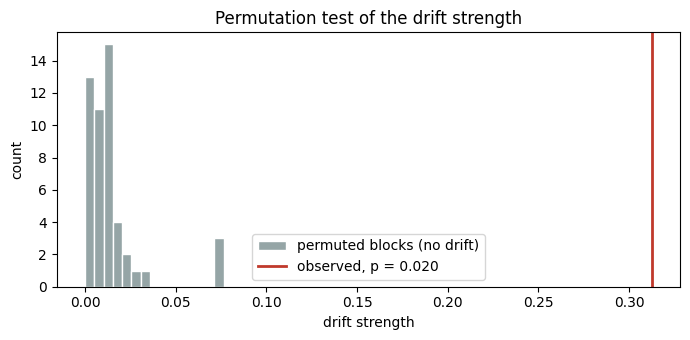

Triggered / evaluated checks per class and criterion:

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,False,2/2,9/36,0/2
1,False,2/2,9/36,0/2


Clusters (distances in standardised feature space; centroid shift threshold 0.37, spread change threshold 10%):

,class,n before,n after,status,centroid shift,spread before,spread after,spread change
cluster,,,,,,,,
0,0,138,422,tracked,1.504,2.189,2.079,-5.0%
1,0,129,303,tracked,1.669,2.088,2.147,+2.9%
2,1,367,108,tracked,1.768,2.103,2.061,-2.0%
3,1,366,167,tracked,1.498,2.055,2.092,+1.8%


Change of per-cluster statistics in standard deviations (bold: above `thr_desc_stats` = 0.2):

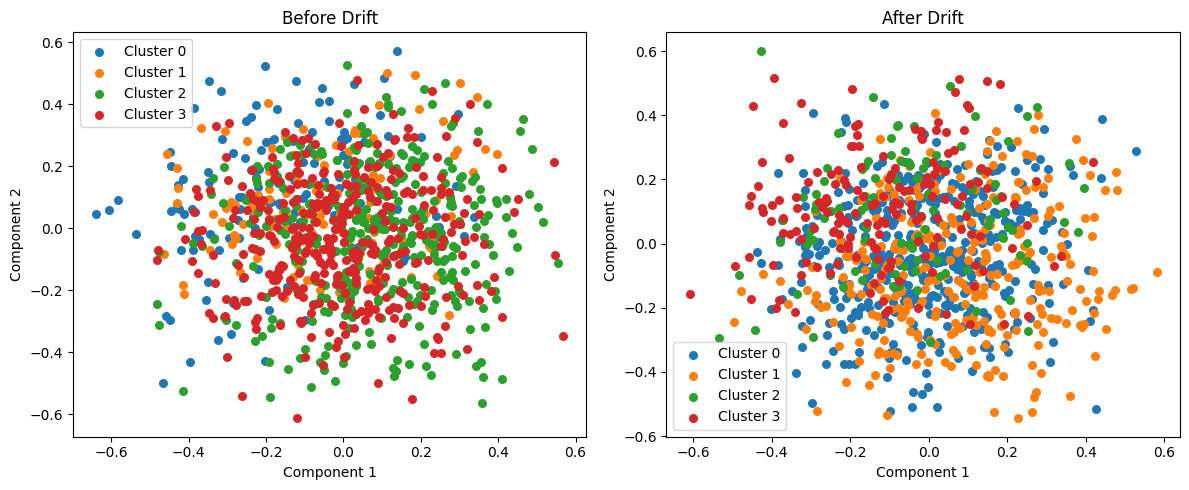

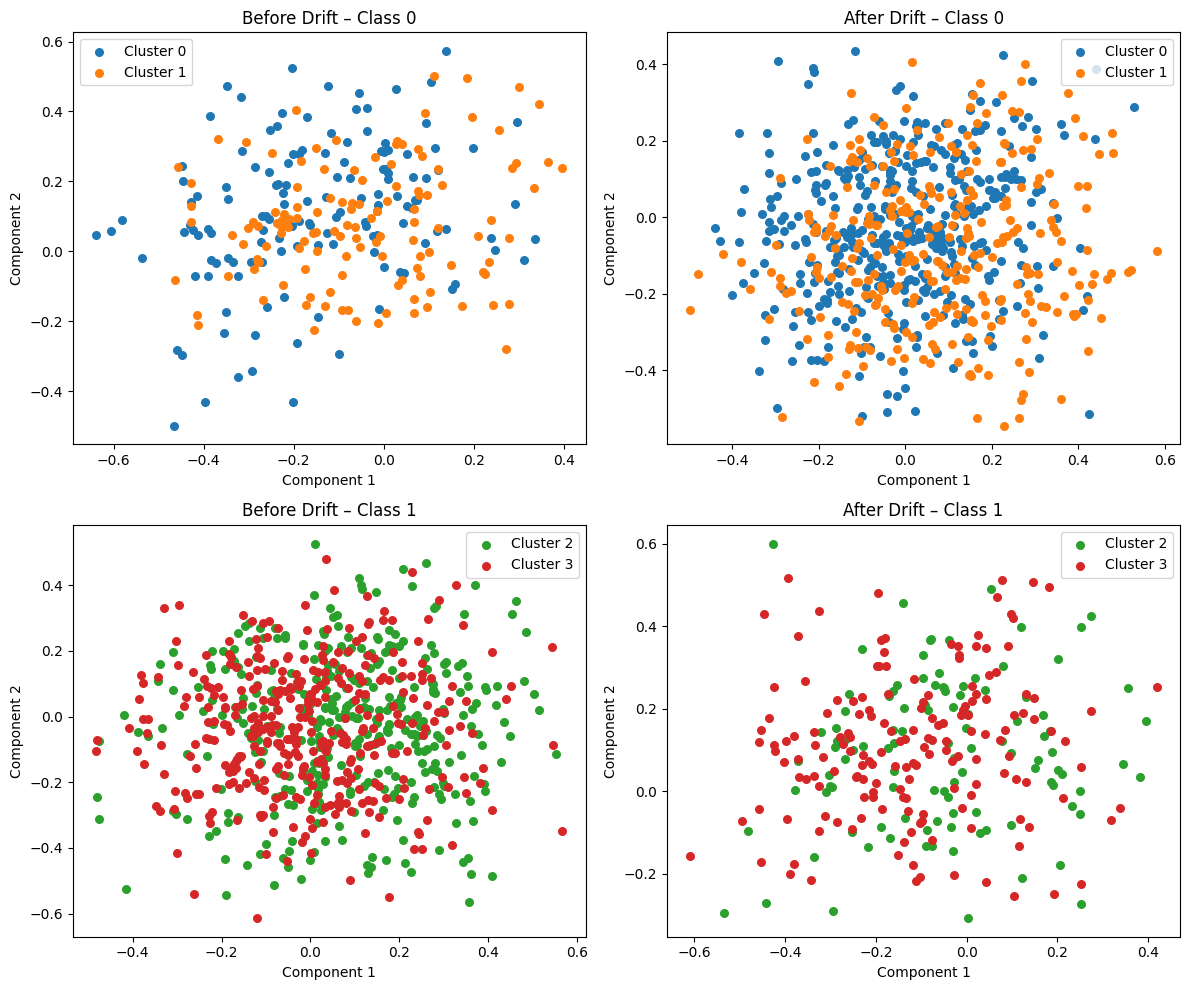

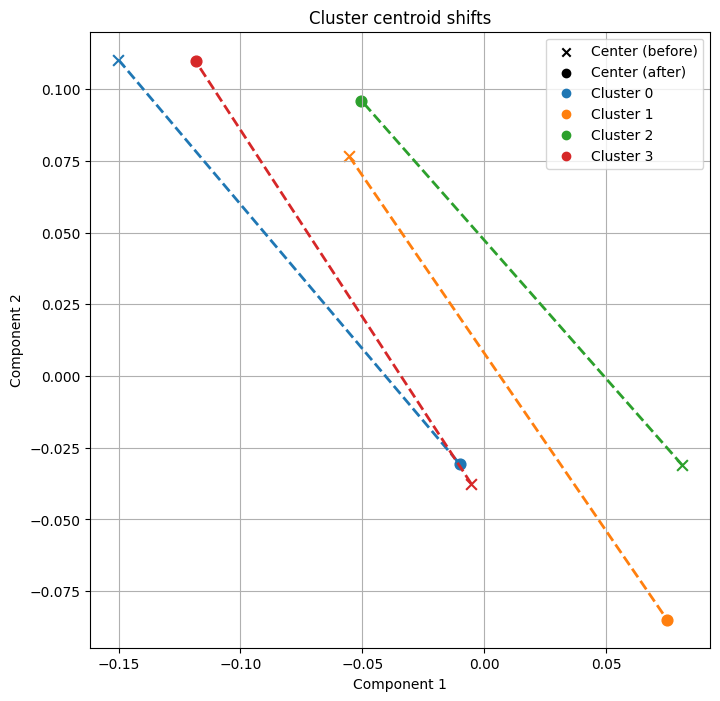

In [11]:
run_experiment(
    DatasetType.RandomTreeMulti,
    boxes=(0, 10),
    num_windows=30,
    window_length=SIZE_OF_BLOCK,
    drift_positions=[10_000, 20_000],
    drift_duration=1,
)

**Analysis**

* The class priors change strongly: class 0 goes from 27% to 73% of the samples.
* Of the features, essentially only **`x1`** changes. Its class-0 and class-1 values are swapped (class mean 0.27 ↔ 0.58), with KS p < 0.001 and JS 0.57 / 0.17. The other features only reach borderline p-values (0.02–0.05).
* **Clustering dynamics**:
  * The structure is stable (4 tracked clusters).
  * Every centroid shifted, by 1.50–1.77 against a threshold of 0.37.
  * The per-cluster statistics attribute the shift to `x1`, which moves by 1.3–1.7σ in every cluster. The few other flagged values are just above the 0.2σ threshold (e.g. `x0` +0.29σ in cluster 0).
* The detector compares classes separately, so the class-prior change itself is not one of its criteria; it shows only in the cluster sizes (e.g. cluster 0: 138 → 422 samples).

## 6. Summary

Decisions of the three detectors on the drifted blocks above, and on two blocks drawn **before** the drift (no drift, so every alarm is a false alarm).

In [12]:
def decisions(dsdd, stdd, cbdd):
    return {
        "descriptive statistics": dsdd.drift_flag,
        "statistical tests": stdd.drift_flag,
        "clustering": cbdd.drift_flag,
        "clustering strength": cbdd.strength_of_drift,
        "clustering p-value": cbdd.p_value,
    }


drifted = pd.DataFrame({name: decisions(*detectors) for name, detectors in RESULTS.items()}).T

control = {}
for dataset_type in [DatasetType.SEA, DatasetType.Hyperplane, DatasetType.RBF, DatasetType.LWI]:
    # Both blocks come from the concept before the drift.
    blocks = load_blocks(dataset_type, n_samples_before=2 * SIZE_OF_BLOCK, boxes=(0, 1))
    control[dataset_type.name] = decisions(*run_detectors(*blocks))
control["RandomTreeMulti"] = decisions(
    *run_detectors(
        *load_blocks(
            DatasetType.RandomTreeMulti,
            boxes=(0, 5),
            num_windows=30,
            window_length=SIZE_OF_BLOCK,
            drift_positions=[10_000, 20_000],
            drift_duration=1,
        )
    )
)
no_drift = pd.DataFrame(control).T

summary = pd.concat({"drift": drifted, "no drift (control)": no_drift}, names=["blocks", "dataset"])
summary.style.format(precision=3)

**Conclusions**

* On the drifted blocks the clustering detector flags all five datasets.
  * It is the only detector that flags **RBF**, where the change is in the multi-modal structure of the classes and invisible in per-feature statistics.
  * It also flags **SEA**, where the statistical tests miss the drift.
* On the control blocks (no drift) none of the detectors raises an alarm. The clustering p-values are 0.35–1.0.
* With the default `n_permutations=50` the smallest attainable p-value is 1/51 ≈ 0.02. This is why all detected drifts show p = 0.020: the observed strength exceeded every permuted strength. Increase `n_permutations` for a finer p-value.
* Every experiment uses a single seed (`random_seed=42`), so the results illustrate the explanations and are not an evaluation of detection rates.